# Sales Forecasting

## Project Objective

Forecast total Sales for the next **13 complete Sunday–Saturday weeks**. A supplemental study forecasts **three complete calendar months**. The project compares statistical, regression and machine-learning models using chronological validation.

## Libraries and Setup

Pandas and NumPy prepare the data; statsmodels, Prophet, scikit-learn, XGBoost, LightGBM and CatBoost provide the models. Matplotlib produces the figures. The experiment uses seed 42 and one numerical thread where applicable.

Install the pinned requirements, then use **Restart Kernel → Run All**. The setup cell can be rerun to refresh the local helper functions.

In [1]:
from pathlib import Path
from time import perf_counter
from importlib.metadata import version, PackageNotFoundError
import importlib
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from IPython.utils.io import capture_output


def locate_project(start):
    for folder in (start, *start.parents):
        if ((folder / "data/raw/Sales Data.xlsx").is_file()
                and (folder / "predict.py").is_file()):
            return folder
    raise FileNotFoundError(
        "Could not find the Sales Forecasting project. Open the notebook from a folder "
        "containing data/raw/Sales Data.xlsx and predict.py, or one of its subfolders."
    )


def displayed_version(package):
    try:
        return version(package)
    except PackageNotFoundError:
        return "NOT INSTALLED"


PROJECT_ROOT = locate_project(Path.cwd().resolve())
packages = ["pandas", "numpy", "statsmodels", "prophet", "scikit-learn", "xgboost", "lightgbm", "catboost"]
display(pd.DataFrame({"Package": packages, "Version": [displayed_version(p) for p in packages]}))

# Import this project's helpers and refresh them if the setup cell is rerun.
project_path = str(PROJECT_ROOT)
if project_path in sys.path:
    sys.path.remove(project_path)
sys.path.insert(0, project_path)
importlib.invalidate_caches()
loaded = sys.modules.get("predict")
if loaded is not None and Path(getattr(loaded, "__file__", "")).resolve() != PROJECT_ROOT / "predict.py":
    del sys.modules["predict"]
import predict
importlib.reload(predict)
from predict import (
    METRICS, prepare_directories, load_data, save_data_tables,
    numeric_round, calculation_namespace, model_inventories, study_results,
    persist_selected, save_study_tables, timing_summary, plot_eda, plot_study,
    check_results, executive_comparison,
)
started = perf_counter()
prepare_directories(PROJECT_ROOT)
globals().update(calculation_namespace(PROJECT_ROOT))
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 2)

,Package,Version
0,pandas,3.0.6
1,numpy,2.5.3
2,statsmodels,0.15.0
3,prophet,1.4.0
4,scikit-learn,1.9.1
5,xgboost,3.4.1
6,lightgbm,4.7.0
7,catboost,1.2.10


## Data Loading and Quality

The workbook contains Sales transaction lines and Product, Region and Salesperson lookups. I retain the recorded revenue and check dates, numeric amounts, lookup keys and totals before modeling. No difficult observations are removed.

In [2]:
data = load_data(PROJECT_ROOT)
sales = data["sales"]
# Source rows are deliberately omitted from the public report.
# The source hash remains available for checks, rather than filling the visible summary.
display(data["quality"].loc[data["quality"].Check.ne("Source SHA256")])

,Check,Value,Meaning
0,Transaction lines,60097,All lines retained; joins preserve values and ...
1,Historical Sales,89584537.85,Source revenue units; currency unspecified
2,Start date,2021-07-01,Observed source coverage
3,End date,2025-05-31,Observed source coverage
4,Exact duplicate lines,0,No automatic deletion
5,Amount mismatches,0,Sales versus quantity × price; no correction
6,Missing product colours,56,Descriptive lookup field retained
7,Complete weeks,204,"Sunday–Saturday, W-SAT labels"
8,Complete months,47,Complete calendar months only
9,Partial-week Sales,83838.27,Opening July 1–3 remains in source reconciliation


The workbook contains 60,097 transaction lines. Missing product colors do not affect total-revenue forecasting. Currency is unspecified, so monetary values use source revenue units. A day with no recorded transactions does not necessarily mean zero demand.

In [3]:
display(data["recording_by_year"])
display(data["order_keys"].set_index("Order definition"))

,Lines,Orders,Sales,Lines per order
OrderDate,,,,
2021,4138,366,8.07e+06,11.31
2022,2246,2246,1.20e+07,1.00
2023,16676,1015,2.43e+07,16.43
2024,26758,1521,3.25e+07,17.59
2025,10279,714,1.27e+07,14.40


,Orders,AOV,Lines per order,Total Sales
Order definition,,,,
Order number,5762,15547.47,10.43,8.96e+07
Order number + date,5862,15282.25,10.25,8.96e+07


### Data Quality Notes

The 2022 records contain 2,246 lines and 2,246 order numbers in a contiguous appended block. Other years contain many lines per order. This difference may reflect a change in how the source was recorded; the revenue is retained as supplied.

There are 100 order numbers appearing on multiple dates. The tables compare order-number-only and order-number/date definitions. Order count, average order value and lines per order change, but total Sales does not. Source-system information is needed to decide which key is correct.

### Dataset Integration

Many-to-one joins add product and region descriptions. Checks confirm that all transaction fields, row order and total Sales are preserved.

In [4]:
enriched_sales = data["enriched"]
assert len(enriched_sales) == len(sales) == 60097
pd.testing.assert_frame_equal(enriched_sales[sales.columns], sales)
# Keep enriched transaction rows local; publish aggregate analysis only.
save_data_tables(data, PROJECT_ROOT)

## Exploratory Data Analysis

These charts describe the full workbook. The trailing average helps show longer-term movement; it is not a forecasting feature. Weekly EDA uses the same Sunday–Saturday boundaries as the models.

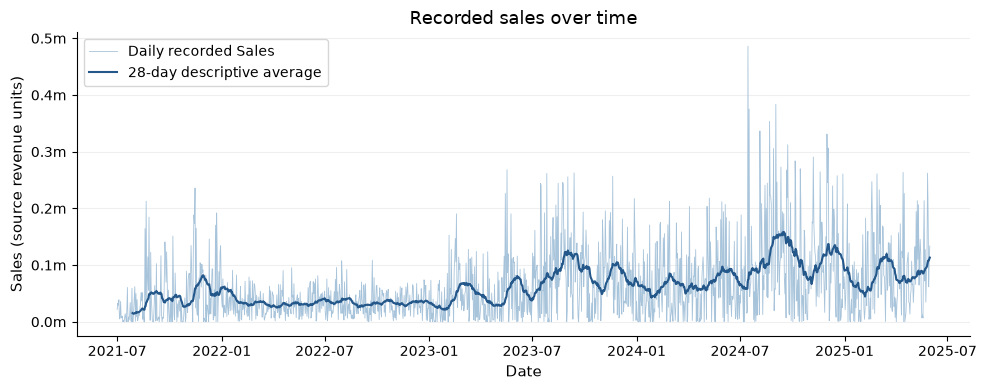

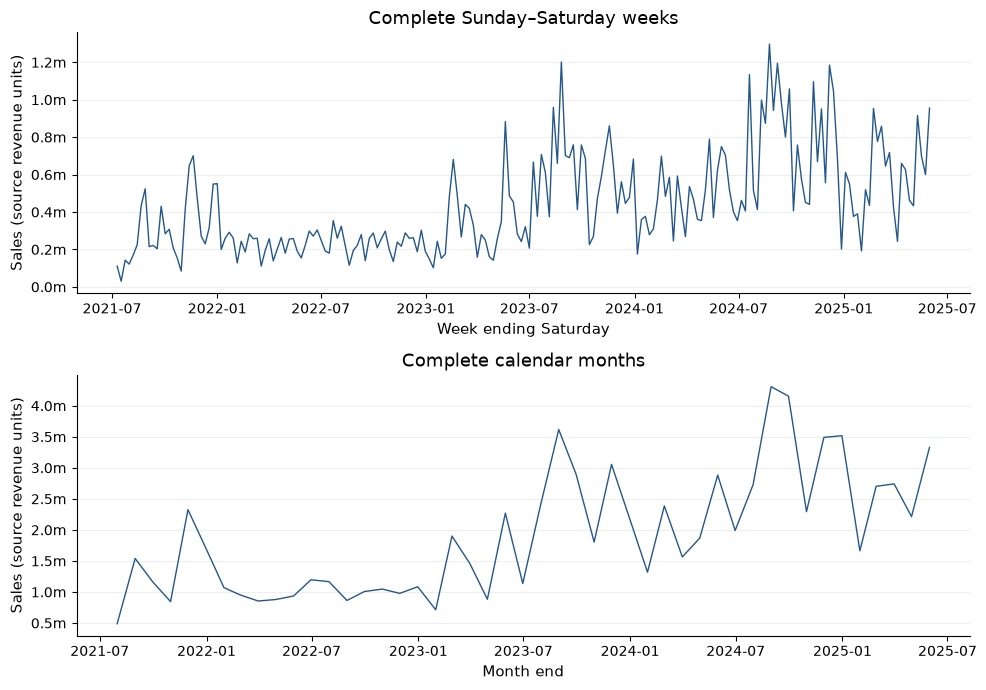

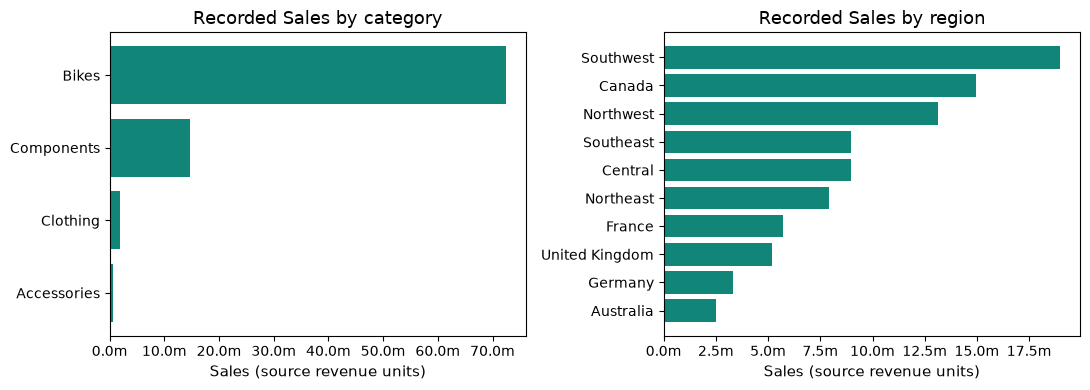

In [5]:
eda_figures = plot_eda(data, PROJECT_ROOT)
for figure in eda_figures:
    display(figure)

Recorded Sales grow over time but remain volatile. Bikes account for most revenue, making total Sales sensitive to changes in that category. The unusual 2022 recording pattern limits how confidently this growth can be interpreted.

## Time-Series Construction

Missing dates within the extract are filled with zero recorded revenue. Complete weeks run Sunday–Saturday and use Saturday labels (`W-SAT`). Complete calendar months use month-end labels.

The opening July 1–3, 2021 bucket is a partial week: it is excluded from weekly modeling but included when checking source totals. July remains a complete month. This produces 204 weekly and 47 monthly observations.

In [6]:
weekly = data["weekly"]
monthly = data["monthly"]
display(pd.DataFrame([
    {"Target": name.title(), "Observations": len(data[name]), "First label": data[name].index[0],
     "Last label": data[name].index[-1], "Complete-period Sales": data[name].sum(),
     "Partial-boundary Sales": data["partial"][name].sum()}
    for name in ["weekly", "monthly"]
]))
assert len(weekly) == 204 and len(monthly) == 47
for name in ["weekly", "monthly"]:
    assert np.isclose(data[name].sum() + data["partial"][name].sum(), sales.Sales.sum())

,Target,Observations,First label,Last label,Complete-period Sales,Partial-boundary Sales
0,Weekly,204,2021-07-10,2025-05-31,8.95e+07,83838.27
1,Monthly,47,2021-07-31,2025-05-31,8.96e+07,0.00


## Evaluation Metrics

I used **WAPE** as the primary selection metric because it measures total absolute forecast error relative to total Sales: `100 × sum(|prediction − actual|) / sum(|actual|)`. Development results average the four fold scores.

- **MAPE** averages each period's absolute percentage error, giving low-sales periods more influence than WAPE. It is undefined if any actual is zero; those periods are not silently omitted.
- **sMAPE** expresses absolute error relative to the average magnitude of actual and predicted Sales. A zero/zero pair contributes zero.
- **MAE** is average absolute error in revenue units. **RMSE** gives large errors more weight.
- **MASE** divides MAE by the training-only seasonal-naive error scale, using period **52 weekly** and **12 monthly**. Below one means less error than that historical scale.
- **Bias** is average prediction minus actual; positive values indicate overforecasting. **Bias %** expresses summed signed error relative to total absolute actual Sales.

All predictions, including transformed-target models, are scored in original revenue units.

### Features and Seasonality

Lag features use earlier Sales, such as the preceding week or the same week a year earlier. Rolling means, medians, variation and ranges summarize recent history. Every rolling feature is shifted to exclude the current target; the 104-week lag is used only when sufficient history is available.

Fourier terms represent annual and shorter seasonal cycles; calendar features describe dates known in advance. Machine-learning forecasts are recursive: each later forecast uses earlier predictions rather than future actual Sales.

Additive seasonality assumes a similar absolute seasonal lift (`Y = Trend + Seasonal + Error`). Multiplicative seasonality scales that lift with the Sales level (`Y = Trend × Seasonal × Error`). The search compares these assumptions and raw, log1p and valid Box–Cox targets using validation accuracy.

## Validation Strategy

I used chronological validation because future observations must not enter training. Expanding windows retain earlier history while adding new observations. Inner folds choose settings; later outer folds evaluate those choices.

- **Weekly:** four outer folds each forecast 13 weeks. Two earlier 13-week inner folds select settings by mean WAPE. The weekly family or ensemble is selected by mean outer WAPE, with RMSE breaking ties. Final settings use the 191-week development prefix.
- **Monthly:** four outer folds each forecast three complete months. Two earlier three-month inner folds choose across the monthly pool, so the selected model may differ by fold. Final settings use the 44 months through February 2025.

Exact inner-score ties use candidate ID for a deterministic result. Ensemble weights also use inner folds only. Retrospective specifications and predictions are fixed before scoring; selecting another model after seeing those scores would invalidate this selection rule.

The final periods are **locked retrospective holdouts**: they were excluded from tuning but had already been examined in earlier analysis. The full-series EDA is descriptive only. Fresh future observations are required for independent confirmation.

### Forecasting Calculations

The collapsed cells below contain the full calculations for both studies, including segment forecasts, ensembles, seasonal comparisons and aggregation sensitivity. The following sections summarize their results.

In [7]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_75:
        from pathlib import Path
        import json, hashlib, time, warnings, logging, platform, importlib.util
        from importlib.metadata import version
        import numpy as np
        import pandas as pd
        import matplotlib.pyplot as plt
        from IPython.display import display, Markdown
        from scipy import stats, special, optimize
        from statsmodels.tsa.holtwinters import ExponentialSmoothing
        from statsmodels.tsa.arima.model import ARIMA
        from statsmodels.tsa.statespace.sarimax import SARIMAX
        from statsmodels.tsa.seasonal import STL
        from statsmodels.tsa.forecasting.theta import ThetaModel
        from sklearn.linear_model import Ridge, HuberRegressor
        from sklearn.preprocessing import StandardScaler
        from sklearn.pipeline import make_pipeline
        from sklearn.ensemble import (
            ExtraTreesRegressor,
            RandomForestRegressor,
            GradientBoostingRegressor,
            HistGradientBoostingRegressor,
        )
        from threadpoolctl import threadpool_limits
        from prophet import Prophet
        from cmdstanpy import disable_logging
        from xgboost import XGBRegressor

        r_root = PROJECT_ROOT
        r_source = RAW_DATA_PATH
        r_source_hash = hashlib.sha256(r_source.read_bytes()).hexdigest()
        r_sheets = pd.read_excel(r_source, sheet_name=None)
        r_tx = r_sheets["Sales"].copy()
        r_tx["OrderDate"] = (
            pd.to_datetime(r_tx.OrderDate, unit="D", origin="1899-12-30")
            if pd.api.types.is_numeric_dtype(r_tx.OrderDate)
            else pd.to_datetime(r_tx.OrderDate)
        )
        r_inventory = pd.DataFrame(
            [
                dict(
                    sheet=k,
                    rows=len(v),
                    columns=len(v.columns),
                    nulls=int(v.isna().sum().sum()),
                    duplicates=int(v.duplicated().sum()),
                )
                for k, v in r_sheets.items()
            ]
        )
        assert r_tx[["OrderDate", "Sales", "Quantity", "Unit Price"]].notna().all().all()
        assert (r_tx[["Sales", "Quantity", "Unit Price"]] > 0).all().all()
        r_tx["amount_mismatch"] = ~np.isclose(
            r_tx.Sales, r_tx.Quantity * r_tx["Unit Price"], atol=0.01, rtol=1e-6
        )
        for sheet, key in [
            ("Product", "ProductKey"),
            ("Region", "SalesTerritoryKey"),
            ("Salesperson", "EmployeeKey"),
        ]:
            assert r_sheets[sheet][key].is_unique and r_sheets[sheet][key].notna().all()
            assert r_tx[key].isin(r_sheets[sheet][key]).all()
            r_tx = r_tx.merge(
                r_sheets[sheet], on=key, how="left", validate="many_to_one", sort=False
            )
        assert len(r_tx) == len(r_sheets["Sales"])
        assert np.isclose(r_tx.Sales.sum(), r_sheets["Sales"].Sales.sum())
        r_calendar = pd.date_range(r_tx.OrderDate.min(), r_tx.OrderDate.max(), freq="D")
        r_daily = r_tx.groupby("OrderDate").Sales.sum().reindex(r_calendar, fill_value=0.0)
        r_buckets = r_daily.resample("W-SAT").agg(["sum", "size"])
        r_y = r_buckets.loc[r_buckets["size"].eq(7), "sum"].rename("Sales").asfreq("W-SAT")
        r_development = r_y.iloc[:-13].copy()
        r_origins = [len(r_development) - 52 + i * 13 for i in range(4)]
        r_holdout_origin = len(r_development)
        assert (
            len(r_y) == 204
            and r_origins == [139, 152, 165, 178]
            and r_holdout_origin == 191
        )
        r_plan = pd.DataFrame(
            [
                dict(
                    fold=i + 1,
                    train_weeks=o,
                    train_end=r_y.index[o - 1],
                    validation_start=r_y.index[o],
                    validation_end=r_y.index[o + 12],
                    inner_origins=[o - 26, o - 13],
                )
                for i, o in enumerate(r_origins)
            ]
        )
        r_versions = {
            p: version(p)
            for p in [
                "numpy",
                "pandas",
                "scipy",
                "statsmodels",
                "scikit-learn",
                "prophet",
                "xgboost",
                "nbformat",
            ]
        }
        r_required_versions = {"lightgbm": "4.7.0", "catboost": "1.2.10"}
        r_optional = {}
        for pkg, expected_version in r_required_versions.items():
            try:
                __import__(pkg)
                installed_version = version(pkg)
            except Exception as exc:
                raise RuntimeError(
                    f"Required forecasting dependency {pkg}=={expected_version} is unavailable. "
                    "Install requirements.txt before reproducing the frozen competition."
                ) from exc
            if installed_version != expected_version:
                raise RuntimeError(
                    f"Expected {pkg}=={expected_version}; found {installed_version}. "
                    "Install the pinned requirements rather than changing the frozen family set."
                )
            r_optional[pkg] = installed_version
        logging.getLogger("prophet").setLevel(logging.ERROR)
        logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
        pd.set_option("display.max_columns", 30)
        print("Source SHA256:", r_source_hash, "Python:", platform.python_version())
        print("Packages:", r_versions, "Pinned dependencies:", r_optional)
        display(r_inventory, r_plan)
        print(
            "Revenue reconciliation:",
            r_tx.Sales.sum(),
            "complete weeks:",
            len(r_y),
            "excluded boundary buckets:",
            r_buckets.loc[r_buckets["size"].ne(7)].to_dict("index"),
        )
        print(
            "No recorded sales days:",
            int(r_daily.eq(0).sum()),
            "amount mismatches:",
            int(r_tx.amount_mismatch.sum()),
        )
c_cell_times.append(dict(Scope='Shared', Stage='Source, environment and weekly boundaries', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [8]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    r_metric_names = ["MAPE", "WAPE", "sMAPE", "MAE", "RMSE", "MASE", "Bias", "Bias_pct"]


    def r_metrics(actual, predicted, training, period=52):
        a = np.asarray(actual, dtype=float)
        p = np.asarray(predicted, dtype=float)
        tr = np.asarray(training, dtype=float)
        assert (
            a.shape == p.shape
            and len(a) > 0
            and np.isfinite(a).all()
            and np.isfinite(p).all()
        )
        e = p - a
        ae = np.abs(e)
        den = np.abs(a).sum()
        sd = np.abs(a) + np.abs(p)
        scale = np.mean(np.abs(tr[period:] - tr[:-period])) if len(tr) > period else np.nan
        nz = np.abs(a) > 0
        return dict(
            MAPE=100 * np.mean(ae / np.abs(a)) if nz.all() else np.nan,
            WAPE=100 * ae.sum() / den if den else np.nan,
            sMAPE=np.mean(np.divide(200 * ae, sd, out=np.zeros_like(ae), where=sd != 0)),
            MAE=ae.mean(),
            RMSE=np.sqrt(np.mean(e**2)),
            MASE=ae.mean() / scale if scale > 0 else np.nan,
            Bias=e.mean(),
            Bias_pct=100 * e.sum() / den if den else np.nan,
            MAPE_nonzero_only=100 * np.mean(ae[nz] / np.abs(a[nz])) if nz.any() else np.nan,
            nonzero_actual_pct=100 * nz.mean(),
            n=len(a),
        )


    def r_strict_mean(s):
        return s.mean() if s.notna().all() else np.nan


    r_probe = r_metrics([1, 9], [2, 9], np.arange(1, 61))
    assert np.isclose(r_probe["MAPE"], 50) and np.isclose(r_probe["WAPE"], 10)
    assert np.isnan(r_metrics([0, 1], [0, 1], np.arange(1, 61))["MAPE"])
    assert r_metrics([0, 0], [0, 0], np.arange(1, 61))["sMAPE"] == 0
    print("Metric assertions passed; zero actuals never silently dropped.")
    display(
        pd.DataFrame(
            [
                dict(
                    scope="all complete weeks",
                    n=len(r_y),
                    zeros=int(r_y.eq(0).sum()),
                    minimum=r_y.min(),
                    median=r_y.median(),
                    below_1pct_development_median=int(
                        (r_y < 0.01 * r_development.median()).sum()
                    ),
                ),
                dict(
                    scope="development",
                    n=len(r_development),
                    zeros=int(r_development.eq(0).sum()),
                    minimum=r_development.min(),
                    median=r_development.median(),
                    below_1pct_development_median=int(
                        (r_development < 0.01 * r_development.median()).sum()
                    ),
                ),
            ]
        )
    )
c_cell_times.append(dict(Scope='Shared', Stage='Metric definitions and zero checks', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [9]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_78:
        from io import StringIO

        r_legacy = pd.read_csv(
            StringIO(
                "model,fold,forecast_origin,forecast_horizon,week_end,actual,predicted,error,absolute_error\nSeasonal Naive,1,2024-06-01,1,2024-06-08,703467.67,281925.61,-421542.06000000006,421542.06000000006\nSeasonal Naive,1,2024-06-01,2,2024-06-15,518828.46,242116.95,-276711.51,276711.51\nSeasonal Naive,1,2024-06-01,3,2024-06-22,400876.3,321900.88,-78975.41999999998,78975.41999999998\nSeasonal Naive,1,2024-06-01,4,2024-06-29,353880.75,206895.83,-146984.92,146984.92\nSeasonal Naive,1,2024-06-01,5,2024-07-06,462405.53,667226.28,204820.75,204820.75\nSeasonal Naive,1,2024-06-01,6,2024-07-13,405221.02,376892.63,-28328.390000000014,28328.390000000014\nSeasonal Naive,1,2024-06-01,7,2024-07-20,1134208.88,707585.51,-426623.3699999999,426623.3699999999\nSeasonal Naive,1,2024-06-01,8,2024-07-27,515082.81,610959.75,95876.94,95876.94\nSeasonal Naive,1,2024-06-01,9,2024-08-03,413256.16,374402.49,-38853.669999999984,38853.669999999984\nSeasonal Naive,1,2024-06-01,10,2024-08-10,997836.35,958758.92,-39077.429999999935,39077.429999999935\nSeasonal Naive,1,2024-06-01,11,2024-08-17,873677.59,659556.63,-214120.95999999996,214120.95999999996\nSeasonal Naive,1,2024-06-01,12,2024-08-24,1296717.38,1201439.68,-95277.69999999995,95277.69999999995\nSeasonal Naive,1,2024-06-01,13,2024-08-31,943078.63,701618.99,-241459.64,241459.64\nSeasonal Naive,2,2024-08-31,1,2024-09-07,1194914.05,690337.4199999999,-504576.6300000001,504576.6300000001\nSeasonal Naive,2,2024-08-31,2,2024-09-14,980218.47,759082.32,-221136.15000000002,221136.15000000002\nSeasonal Naive,2,2024-08-31,3,2024-09-21,799828.83,413047.7,-386781.12999999995,386781.12999999995\nSeasonal Naive,2,2024-08-31,4,2024-09-28,1058074.16,758072.53,-300001.6299999999,300001.6299999999\nSeasonal Naive,2,2024-08-31,5,2024-10-05,406165.04,687089.72,280924.68,280924.68\nSeasonal Naive,2,2024-08-31,6,2024-10-12,757911.37,226089.28999999998,-531822.0800000001,531822.0800000001\nSeasonal Naive,2,2024-08-31,7,2024-10-19,575150.37,268677.85,-306472.52,306472.52\nSeasonal Naive,2,2024-08-31,8,2024-10-26,451033.02,471700.41000000003,20667.390000000014,20667.390000000014\nSeasonal Naive,2,2024-08-31,9,2024-11-02,440981.48,589467.27,148485.79000000004,148485.79000000004\nSeasonal Naive,2,2024-08-31,10,2024-11-09,1096256.12,728481.14,-367774.9800000001,367774.9800000001\nSeasonal Naive,2,2024-08-31,11,2024-11-16,669241.78,860326.22,191084.43999999994,191084.43999999994\nSeasonal Naive,2,2024-08-31,12,2024-11-23,950980.91,650514.08,-300466.8300000001,300466.8300000001\nSeasonal Naive,2,2024-08-31,13,2024-11-30,556282.21,393760.25,-162521.95999999996,162521.95999999996\nSeasonal Naive,3,2024-11-30,1,2024-12-07,1185013.55,561854.8,-623158.75,623158.75\nSeasonal Naive,3,2024-11-30,2,2024-12-14,1046506.12,446244.58,-600261.54,600261.54\nSeasonal Naive,3,2024-11-30,3,2024-12-21,684523.8300000001,477692.45,-206831.38000000006,206831.38000000006\nSeasonal Naive,3,2024-11-30,4,2024-12-28,202235.02,682885.59,480650.56999999995,480650.56999999995\nSeasonal Naive,3,2024-11-30,5,2025-01-04,611881.89,175253.95,-436627.94,436627.94\nSeasonal Naive,3,2024-11-30,6,2025-01-11,550235.95,359241.04000000004,-190994.90999999992,190994.90999999992\nSeasonal Naive,3,2024-11-30,7,2025-01-18,376625.16000000003,377045.2,420.03999999997905,420.03999999997905\nSeasonal Naive,3,2024-11-30,8,2025-01-25,390111.49,278522.88,-111588.60999999999,111588.60999999999\nSeasonal Naive,3,2024-11-30,9,2025-02-01,192227.67,309867.98,117640.30999999997,117640.30999999997\nSeasonal Naive,3,2024-11-30,10,2025-02-08,519592.25,464211.55,-55380.70000000001,55380.70000000001\nSeasonal Naive,3,2024-11-30,11,2025-02-15,435610.7,698581.8999999999,262971.1999999999,262971.1999999999\nSeasonal Naive,3,2024-11-30,12,2025-02-22,954018.45,483548.55,-470469.89999999997,470469.89999999997\nSeasonal Naive,3,2024-11-30,13,2025-03-01,776921.1799999999,585390.27,-191530.90999999992,191530.90999999992\nSeasonal Naive,4,2025-03-01,1,2025-03-08,858309.57,245274.00000000003,-613035.57,613035.57\nSeasonal Naive,4,2025-03-01,2,2025-03-15,645030.32,592436.65,-52593.669999999925,52593.669999999925\nSeasonal Naive,4,2025-03-01,3,2025-03-22,718025.44,423837.34,-294188.0999999999,294188.0999999999\nSeasonal Naive,4,2025-03-01,4,2025-03-29,426545.27999999997,268343.35,-158201.93,158201.93\nSeasonal Naive,4,2025-03-01,5,2025-04-05,243191.37,536165.33,292973.95999999996,292973.95999999996\nSeasonal Naive,4,2025-03-01,6,2025-04-12,659572.89,468301.9,-191270.99,191270.99\nSeasonal Naive,4,2025-03-01,7,2025-04-19,626700.98,361050.74,-265650.24,265650.24\nSeasonal Naive,4,2025-03-01,8,2025-04-26,461340.19,353994.97,-107345.22000000003,107345.22000000003\nSeasonal Naive,4,2025-03-01,9,2025-05-03,432936.45,517828.68,84892.22999999998,84892.22999999998\nSeasonal Naive,4,2025-03-01,10,2025-05-10,915685.01,789473.64,-126211.37,126211.37\nSeasonal Naive,4,2025-03-01,11,2025-05-17,698391.01,370324.73,-328066.28,328066.28\nSeasonal Naive,4,2025-03-01,12,2025-05-24,600184.51,621454.19,21269.679999999935,21269.679999999935\nSeasonal Naive,4,2025-03-01,13,2025-05-31,955577.81,749905.76,-205672.05000000005,205672.05000000005\nETS,1,2024-06-01,1,2024-06-08,703467.67,531429.2317836372,-172038.43821636285,172038.43821636285\nETS,1,2024-06-01,2,2024-06-15,518828.46,495675.985953604,-23152.474046396033,23152.474046396033\nETS,1,2024-06-01,3,2024-06-22,400876.3,549765.9906155628,148889.69061556278,148889.69061556278\nETS,1,2024-06-01,4,2024-06-29,353880.75,462207.60967664054,108326.85967664054,108326.85967664054\nETS,1,2024-06-01,5,2024-07-06,462405.53,672281.2045978879,209875.6745978879,209875.6745978879\nETS,1,2024-06-01,6,2024-07-13,405221.02,530742.2914431297,125521.27144312963,125521.27144312963\nETS,1,2024-06-01,7,2024-07-20,1134208.88,723593.5397585655,-410615.3402414344,410615.3402414344\nETS,1,2024-06-01,8,2024-07-27,515082.81,641285.5724040358,126202.76240403584,126202.76240403584\nETS,1,2024-06-01,9,2024-08-03,413256.16,589206.3682873101,175950.20828731015,175950.20828731015\nETS,1,2024-06-01,10,2024-08-10,997836.35,758362.1397678504,-239474.21023214958,239474.21023214958\nETS,1,2024-06-01,11,2024-08-17,873677.59,684729.0701672721,-188948.51983272785,188948.51983272785\nETS,1,2024-06-01,12,2024-08-24,1296717.38,913708.9150214386,-383008.4649785613,383008.4649785613\nETS,1,2024-06-01,13,2024-08-31,943078.63,645951.9136590321,-297126.7163409679,297126.7163409679\nETS,2,2024-08-31,1,2024-09-07,1194914.05,828934.6974245507,-365979.3525754494,365979.3525754494\nETS,2,2024-08-31,2,2024-09-14,980218.47,846689.3410404227,-133529.1289595773,133529.1289595773\nETS,2,2024-08-31,3,2024-09-21,799828.83,622164.0709113994,-177664.75908860052,177664.75908860052\nETS,2,2024-08-31,4,2024-09-28,1058074.16,904439.3982946742,-153634.76170532568,153634.76170532568\nETS,2,2024-08-31,5,2024-10-05,406165.04,822934.1313711067,416769.09137110674,416769.09137110674\nETS,2,2024-08-31,6,2024-10-12,757911.37,385004.71342354605,-372906.65657645394,372906.65657645394\nETS,2,2024-08-31,7,2024-10-19,575150.37,463773.76827467885,-111376.60172532115,111376.60172532115\nETS,2,2024-08-31,8,2024-10-26,451033.02,547949.9446877628,96916.92468776274,96916.92468776274\nETS,2,2024-08-31,9,2024-11-02,440981.48,682877.2351703132,241895.75517031318,241895.75517031318\nETS,2,2024-08-31,10,2024-11-09,1096256.12,991410.4487890699,-104845.67121093022,104845.67121093022\nETS,2,2024-08-31,11,2024-11-16,669241.78,1147616.6736074071,478374.8936074071,478374.8936074071\nETS,2,2024-08-31,12,2024-11-23,950980.91,880146.540298378,-70834.36970162205,70834.36970162205\nETS,2,2024-08-31,13,2024-11-30,556282.21,549653.434890158,-6628.775109841954,6628.775109841954\nETS,3,2024-11-30,1,2024-12-07,1185013.55,627449.1730004706,-557564.3769995294,557564.3769995294\nETS,3,2024-11-30,2,2024-12-14,1046506.12,547612.126528032,-498893.993471968,498893.993471968\nETS,3,2024-11-30,3,2024-12-21,684523.8300000001,725214.126514805,40690.29651480494,40690.29651480494\nETS,3,2024-11-30,4,2024-12-28,202235.02,844303.5112512289,642068.4912512288,642068.4912512288\nETS,3,2024-11-30,5,2025-01-04,611881.89,276435.6775269356,-335446.2124730644,335446.2124730644\nETS,3,2024-11-30,6,2025-01-11,550235.95,429229.276624611,-121006.67337538896,121006.67337538896\nETS,3,2024-11-30,7,2025-01-18,376625.16000000003,490743.97376630455,114118.81376630452,114118.81376630452\nETS,3,2024-11-30,8,2025-01-25,390111.49,388038.76379356725,-2072.726206432737,2072.726206432737\nETS,3,2024-11-30,9,2025-02-01,192227.67,269254.9068109313,77027.23681093127,77027.23681093127\nETS,3,2024-11-30,10,2025-02-08,519592.25,553311.7938167569,33719.54381675692,33719.54381675692\nETS,3,2024-11-30,11,2025-02-15,435610.7,792722.4532254785,357111.7532254785,357111.7532254785\nETS,3,2024-11-30,12,2025-02-22,954018.45,625523.1348140044,-328495.31518599554,328495.31518599554\nETS,3,2024-11-30,13,2025-03-01,776921.1799999999,572166.7933949996,-204754.38660500036,204754.38660500036\nETS,4,2025-03-01,1,2025-03-08,858309.57,551000.4662793828,-307309.10372061713,307309.10372061713\nETS,4,2025-03-01,2,2025-03-15,645030.32,607842.5797277002,-37187.740272299736,37187.740272299736\nETS,4,2025-03-01,3,2025-03-22,718025.44,547464.5819629257,-170560.8580370742,170560.8580370742\nETS,4,2025-03-01,4,2025-03-29,426545.27999999997,456866.35231051355,30321.072310513584,30321.072310513584\nETS,4,2025-03-01,5,2025-04-05,243191.37,544663.4501993863,301472.08019938634,301472.08019938634\nETS,4,2025-03-01,6,2025-04-12,659572.89,530872.5085036854,-128700.38149631466,128700.38149631466\nETS,4,2025-03-01,7,2025-04-19,626700.98,484098.2003101669,-142602.77968983306,142602.77968983306\nETS,4,2025-03-01,8,2025-04-26,461340.19,445335.15640059183,-16005.033599408169,16005.033599408169\nETS,4,2025-03-01,9,2025-05-03,432936.45,561206.1915992362,128269.74159923621,128269.74159923621\nETS,4,2025-03-01,10,2025-05-10,915685.01,681017.9528464619,-234667.0571535381,234667.0571535381\nETS,4,2025-03-01,11,2025-05-17,698391.01,694865.8280891933,-3525.1819108066848,3525.1819108066848\nETS,4,2025-03-01,12,2025-05-24,600184.51,632072.8892046595,31888.37920465949,31888.37920465949\nETS,4,2025-03-01,13,2025-05-31,955577.81,684428.9555618182,-271148.85443818185,271148.85443818185\nSARIMAX,1,2024-06-01,1,2024-06-08,703467.67,699463.9239307623,-4003.7460692377063,4003.7460692377063\nSARIMAX,1,2024-06-01,2,2024-06-15,518828.46,726558.1449605722,207729.68496057222,207729.68496057222\nSARIMAX,1,2024-06-01,3,2024-06-22,400876.3,712036.6036622031,311160.3036622031,311160.3036622031\nSARIMAX,1,2024-06-01,4,2024-06-29,353880.75,721584.3194218563,367703.5694218563,367703.5694218563\nSARIMAX,1,2024-06-01,5,2024-07-06,462405.53,701635.4553914648,239229.92539146473,239229.92539146473\nSARIMAX,1,2024-06-01,6,2024-07-13,405221.02,713797.1274701613,308576.1074701613,308576.1074701613\nSARIMAX,1,2024-06-01,7,2024-07-20,1134208.88,700658.3974101782,-433550.4825898217,433550.4825898217\nSARIMAX,1,2024-06-01,8,2024-07-27,515082.81,704569.75469246,189486.94469245995,189486.94469245995\nSARIMAX,1,2024-06-01,9,2024-08-03,413256.16,713543.9481754458,300287.7881754458,300287.7881754458\nSARIMAX,1,2024-06-01,10,2024-08-10,997836.35,691187.1615250403,-306649.1884749597,306649.1884749597\nSARIMAX,1,2024-06-01,11,2024-08-17,873677.59,702636.945754515,-171040.64424548496,171040.64424548496\nSARIMAX,1,2024-06-01,12,2024-08-24,1296717.38,681874.8218818941,-614842.5581181057,614842.5581181057\nSARIMAX,1,2024-06-01,13,2024-08-31,943078.63,701029.3137513084,-242049.31624869164,242049.31624869164\nSARIMAX,2,2024-08-31,1,2024-09-07,1194914.05,936868.7399134455,-258045.3100865545,258045.3100865545\nSARIMAX,2,2024-08-31,2,2024-09-14,980218.47,936868.7409196788,-43349.72908032115,43349.72908032115\nSARIMAX,2,2024-08-31,3,2024-09-21,799828.83,936868.7358551656,137039.90585516568,137039.90585516568\nSARIMAX,2,2024-08-31,4,2024-09-28,1058074.16,936868.7409048594,-121205.41909514053,121205.41909514053\nSARIMAX,2,2024-08-31,5,2024-10-05,406165.04,936868.7398660531,530703.6998660532,530703.6998660532\nSARIMAX,2,2024-08-31,6,2024-10-12,757911.37,936868.7331189481,178957.36311894807,178957.36311894807\nSARIMAX,2,2024-08-31,7,2024-10-19,575150.37,936868.7337422512,361718.3637422512,361718.3637422512\nSARIMAX,2,2024-08-31,8,2024-10-26,451033.02,936868.7367136584,485835.7167136584,485835.7167136584\nSARIMAX,2,2024-08-31,9,2024-11-02,440981.48,936868.738437282,495887.25843728206,495887.25843728206\nSARIMAX,2,2024-08-31,10,2024-11-09,1096256.12,936868.7404717985,-159387.37952820165,159387.37952820165\nSARIMAX,2,2024-08-31,11,2024-11-16,669241.78,936868.7424013052,267626.9624013052,267626.9624013052\nSARIMAX,2,2024-08-31,12,2024-11-23,950980.91,936868.7393306337,-14112.170669366373,14112.170669366373\nSARIMAX,2,2024-08-31,13,2024-11-30,556282.21,936868.7355728189,380586.52557281894,380586.52557281894\nSARIMAX,3,2024-11-30,1,2024-12-07,1185013.55,738896.4677583687,-446117.08224163135,446117.08224163135\nSARIMAX,3,2024-11-30,2,2024-12-14,1046506.12,672793.0197453913,-373713.10025460867,373713.10025460867\nSARIMAX,3,2024-11-30,3,2024-12-21,684523.8300000001,699750.036707188,15226.206707187928,15226.206707187928\nSARIMAX,3,2024-11-30,4,2024-12-28,202235.02,755133.5922292158,552898.5722292158,552898.5722292158\nSARIMAX,3,2024-11-30,5,2025-01-04,611881.89,614041.5230653725,2159.6330653724726,2159.6330653724726\nSARIMAX,3,2024-11-30,6,2025-01-11,550235.95,666151.0877019366,115915.13770193665,115915.13770193665\nSARIMAX,3,2024-11-30,7,2025-01-18,376625.16000000003,671672.5888980537,295047.4288980537,295047.4288980537\nSARIMAX,3,2024-11-30,8,2025-01-25,390111.49,643844.1595620485,253732.6695620485,253732.6695620485\nSARIMAX,3,2024-11-30,9,2025-02-01,192227.67,652822.5452317984,460594.8752317984,460594.8752317984\nSARIMAX,3,2024-11-30,10,2025-02-08,519592.25,696577.5363919409,176985.2863919409,176985.2863919409\nSARIMAX,3,2024-11-30,11,2025-02-15,435610.7,762994.2840909859,327383.5840909859,327383.5840909859\nSARIMAX,3,2024-11-30,12,2025-02-22,954018.45,702088.0651670037,-251930.3848329963,251930.3848329963\nSARIMAX,3,2024-11-30,13,2025-03-01,776921.1799999999,730944.107576558,-45977.07242344192,45977.07242344192\nSARIMAX,4,2025-03-01,1,2025-03-08,858309.57,666345.3442644749,-191964.22573552502,191964.22573552502\nSARIMAX,4,2025-03-01,2,2025-03-15,645030.32,708299.2302047157,63268.910204715794,63268.910204715794\nSARIMAX,4,2025-03-01,3,2025-03-22,718025.44,653765.7594652033,-64259.68053479667,64259.68053479667\nSARIMAX,4,2025-03-01,4,2025-03-29,426545.27999999997,606117.3033833606,179572.02338336065,179572.02338336065\nSARIMAX,4,2025-03-01,5,2025-04-05,243191.37,665801.0634165826,422609.69341658265,422609.69341658265\nSARIMAX,4,2025-03-01,6,2025-04-12,659572.89,646683.9477707371,-12888.942229262902,12888.942229262902\nSARIMAX,4,2025-03-01,7,2025-04-19,626700.98,619485.5919936389,-7215.388006361085,7215.388006361085\nSARIMAX,4,2025-03-01,8,2025-04-26,461340.19,616990.6032829346,155650.41328293463,155650.41328293463\nSARIMAX,4,2025-03-01,9,2025-05-03,432936.45,655938.7791261988,223002.32912619883,223002.32912619883\nSARIMAX,4,2025-03-01,10,2025-05-10,915685.01,720985.7355579506,-194699.27444204944,194699.27444204944\nSARIMAX,4,2025-03-01,11,2025-05-17,698391.01,620137.733998975,-78253.27600102499,78253.27600102499\nSARIMAX,4,2025-03-01,12,2025-05-24,600184.51,680418.5893209657,80234.07932096568,80234.07932096568\nSARIMAX,4,2025-03-01,13,2025-05-31,955577.81,711250.1570760377,-244327.65292396233,244327.65292396233\nProphet,1,2024-06-01,1,2024-06-08,703467.67,514421.2858483242,-189046.38415167585,189046.38415167585\nProphet,1,2024-06-01,2,2024-06-15,518828.46,481170.33701601013,-37658.12298398989,37658.12298398989\nProphet,1,2024-06-01,3,2024-06-22,400876.3,468899.55867604306,68023.25867604307,68023.25867604307\nProphet,1,2024-06-01,4,2024-06-29,353880.75,484297.00545261,130416.25545261003,130416.25545261003\nProphet,1,2024-06-01,5,2024-07-06,462405.53,525908.4643666538,63502.93436665379,63502.93436665379\nProphet,1,2024-06-01,6,2024-07-13,405221.02,573616.486479631,168395.46647963102,168395.46647963102\nProphet,1,2024-06-01,7,2024-07-20,1134208.88,599977.9068695047,-534230.9731304952,534230.9731304952\nProphet,1,2024-06-01,8,2024-07-27,515082.81,601498.4232667699,86415.61326676985,86415.61326676985\nProphet,1,2024-06-01,9,2024-08-03,413256.16,610648.7008979211,197392.54089792114,197392.54089792114\nProphet,1,2024-06-01,10,2024-08-10,997836.35,661843.7591862178,-335992.5908137822,335992.5908137822\nProphet,1,2024-06-01,11,2024-08-17,873677.59,742766.4684255143,-130911.12157448567,130911.12157448567\nProphet,1,2024-06-01,12,2024-08-24,1296717.38,793090.9519398065,-503626.42806019343,503626.42806019343\nProphet,1,2024-06-01,13,2024-08-31,943078.63,765177.4469214135,-177901.18307858647,177901.18307858647\nProphet,2,2024-08-31,1,2024-09-07,1194914.05,726261.409714346,-468652.640285654,468652.640285654\nProphet,2,2024-08-31,2,2024-09-14,980218.47,635889.0674704432,-344329.40252955677,344329.40252955677\nProphet,2,2024-08-31,3,2024-09-21,799828.83,655601.2074787656,-144227.62252123433,144227.62252123433\nProphet,2,2024-08-31,4,2024-09-28,1058074.16,727025.3768818564,-331048.78311814356,331048.78311814356\nProphet,2,2024-08-31,5,2024-10-05,406165.04,731248.1680861494,325083.1280861494,325083.1280861494\nProphet,2,2024-08-31,6,2024-10-12,757911.37,628619.767736373,-129291.60226362699,129291.60226362699\nProphet,2,2024-08-31,7,2024-10-19,575150.37,512219.60560456244,-62930.76439543755,62930.76439543755\nProphet,2,2024-08-31,8,2024-10-26,451033.02,511544.4141968248,60511.39419682475,60511.39419682475\nProphet,2,2024-08-31,9,2024-11-02,440981.48,651321.3091238537,210339.8291238537,210339.8291238537\nProphet,2,2024-08-31,10,2024-11-09,1096256.12,820350.4874224283,-275905.6325775718,275905.6325775718\nProphet,2,2024-08-31,11,2024-11-16,669241.78,882295.6543865553,213053.87438655528,213053.87438655528\nProphet,2,2024-08-31,12,2024-11-23,950980.91,806686.8804806804,-144294.02951931965,144294.02951931965\nProphet,2,2024-08-31,13,2024-11-30,556282.21,684725.8097803162,128443.59978031623,128443.59978031623\nProphet,3,2024-11-30,1,2024-12-07,1185013.55,595947.4713708933,-589066.0786291067,589066.0786291067\nProphet,3,2024-11-30,2,2024-12-14,1046506.12,643144.5707295741,-403361.5492704259,403361.5492704259\nProphet,3,2024-11-30,3,2024-12-21,684523.8300000001,717955.7502391109,33431.92023911083,33431.92023911083\nProphet,3,2024-11-30,4,2024-12-28,202235.02,712855.8018082031,510620.7818082031,510620.7818082031\nProphet,3,2024-11-30,5,2025-01-04,611881.89,606850.3740487923,-5031.5159512077225,5031.5159512077225\nProphet,3,2024-11-30,6,2025-01-11,550235.95,466470.5248070408,-83765.42519295914,83765.42519295914\nProphet,3,2024-11-30,7,2025-01-18,376625.16000000003,379258.3826256795,2633.222625679453,2633.222625679453\nProphet,3,2024-11-30,8,2025-01-25,390111.49,395485.9630059378,5374.47300593782,5374.47300593782\nProphet,3,2024-11-30,9,2025-02-01,192227.67,510949.28542278835,318721.6154227883,318721.6154227883\nProphet,3,2024-11-30,10,2025-02-08,519592.25,674538.0947433605,154945.84474336053,154945.84474336053\nProphet,3,2024-11-30,11,2025-02-15,435610.7,807423.3179214266,371812.6179214266,371812.6179214266\nProphet,3,2024-11-30,12,2025-02-22,954018.45,841366.8545092238,-112651.59549077612,112651.59549077612\nProphet,3,2024-11-30,13,2025-03-01,776921.1799999999,766986.8906199283,-9934.289380071685,9934.289380071685\nProphet,4,2025-03-01,1,2025-03-08,858309.57,660099.9998695096,-198209.57013049035,198209.57013049035\nProphet,4,2025-03-01,2,2025-03-15,645030.32,541370.2526259777,-103660.06737402221,103660.06737402221\nProphet,4,2025-03-01,3,2025-03-22,718025.44,540148.9206863075,-177876.51931369246,177876.51931369246\nProphet,4,2025-03-01,4,2025-03-29,426545.27999999997,595807.5896653362,169262.30966533622,169262.30966533622\nProphet,4,2025-03-01,5,2025-04-05,243191.37,591765.0924197463,348573.72241974634,348573.72241974634\nProphet,4,2025-03-01,6,2025-04-12,659572.89,505974.99524973694,-153597.89475026308,153597.89475026308\nProphet,4,2025-03-01,7,2025-04-19,626700.98,436333.5458426589,-190367.43415734108,190367.43415734108\nProphet,4,2025-03-01,8,2025-04-26,461340.19,479174.3222814471,17834.13228144712,17834.13228144712\nProphet,4,2025-03-01,9,2025-05-03,432936.45,618532.1370553442,185595.68705534417,185595.68705534417\nProphet,4,2025-03-01,10,2025-05-10,915685.01,757004.4623052952,-158680.54769470484,158680.54769470484\nProphet,4,2025-03-01,11,2025-05-17,698391.01,831667.3245253023,133276.31452530227,133276.31452530227\nProphet,4,2025-03-01,12,2025-05-24,600184.51,859128.7329902209,258944.22299022088,258944.22299022088\nProphet,4,2025-03-01,13,2025-05-31,955577.81,865852.4452693484,-89725.3647306516,89725.3647306516\nXGBoost,1,2024-06-01,1,2024-06-08,703467.67,568728.5568299324,-134739.11317006766,134739.11317006766\nXGBoost,1,2024-06-01,2,2024-06-15,518828.46,606459.5380361192,87631.07803611917,87631.07803611917\nXGBoost,1,2024-06-01,3,2024-06-22,400876.3,527374.011469581,126497.71146958106,126497.71146958106\nXGBoost,1,2024-06-01,4,2024-06-29,353880.75,528800.6464539878,174919.8964539878,174919.8964539878\nXGBoost,1,2024-06-01,5,2024-07-06,462405.53,536777.9379085571,74372.4079085571,74372.4079085571\nXGBoost,1,2024-06-01,6,2024-07-13,405221.02,541085.8620888718,135864.84208887175,135864.84208887175\nXGBoost,1,2024-06-01,7,2024-07-20,1134208.88,501328.0714950867,-632880.8085049132,632880.8085049132\nXGBoost,1,2024-06-01,8,2024-07-27,515082.81,493576.76768796373,-21506.04231203627,21506.04231203627\nXGBoost,1,2024-06-01,9,2024-08-03,413256.16,531687.4371419735,118431.27714197355,118431.27714197355\nXGBoost,1,2024-06-01,10,2024-08-10,997836.35,532552.5361094102,-465283.81389058975,465283.81389058975\nXGBoost,1,2024-06-01,11,2024-08-17,873677.59,523056.8328413524,-350620.7571586476,350620.7571586476\nXGBoost,1,2024-06-01,12,2024-08-24,1296717.38,539936.3061279521,-756781.0738720478,756781.0738720478\nXGBoost,1,2024-06-01,13,2024-08-31,943078.63,537401.7815218508,-405676.84847814916,405676.84847814916\nXGBoost,2,2024-08-31,1,2024-09-07,1194914.05,705655.7908528658,-489258.25914713426,489258.25914713426\nXGBoost,2,2024-08-31,2,2024-09-14,980218.47,746268.7277868306,-233949.74221316935,233949.74221316935\nXGBoost,2,2024-08-31,3,2024-09-21,799828.83,694286.6510263066,-105542.1789736934,105542.1789736934\nXGBoost,2,2024-08-31,4,2024-09-28,1058074.16,660961.3611647416,-397112.79883525835,397112.79883525835\nXGBoost,2,2024-08-31,5,2024-10-05,406165.04,712205.920291695,306040.88029169507,306040.88029169507\nXGBoost,2,2024-08-31,6,2024-10-12,757911.37,639508.8135630428,-118402.55643695721,118402.55643695721\nXGBoost,2,2024-08-31,7,2024-10-19,575150.37,570094.580941243,-5055.789058757015,5055.789058757015\nXGBoost,2,2024-08-31,8,2024-10-26,451033.02,570094.580941243,119061.56094124296,119061.56094124296\nXGBoost,2,2024-08-31,9,2024-11-02,440981.48,644884.0996717835,203902.61967178353,203902.61967178353\nXGBoost,2,2024-08-31,10,2024-11-09,1096256.12,643698.5384727188,-452557.5815272813,452557.5815272813\nXGBoost,2,2024-08-31,11,2024-11-16,669241.78,509610.6233195999,-159631.15668040013,159631.15668040013\nXGBoost,2,2024-08-31,12,2024-11-23,950980.91,589047.8955485448,-361933.0144514552,361933.0144514552\nXGBoost,2,2024-08-31,13,2024-11-30,556282.21,519612.8684288168,-36669.34157118318,36669.34157118318\nXGBoost,3,2024-11-30,1,2024-12-07,1185013.55,656165.3883024668,-528848.1616975332,528848.1616975332\nXGBoost,3,2024-11-30,2,2024-12-14,1046506.12,614406.881082725,-432099.238917275,432099.238917275\nXGBoost,3,2024-11-30,3,2024-12-21,684523.8300000001,622978.371639767,-61545.45836023311,61545.45836023311\nXGBoost,3,2024-11-30,4,2024-12-28,202235.02,640410.773839715,438175.75383971503,438175.75383971503\nXGBoost,3,2024-11-30,5,2025-01-04,611881.89,408011.977427731,-203869.91257226904,203869.91257226904\nXGBoost,3,2024-11-30,6,2025-01-11,550235.95,420654.66447429016,-129581.2855257098,129581.2855257098\nXGBoost,3,2024-11-30,7,2025-01-18,376625.16000000003,428397.7221658374,51772.562165837386,51772.562165837386\nXGBoost,3,2024-11-30,8,2025-01-25,390111.49,436060.8735097347,45949.383509734704,45949.383509734704\nXGBoost,3,2024-11-30,9,2025-02-01,192227.67,426017.1318257701,233789.46182577006,233789.46182577006\nXGBoost,3,2024-11-30,10,2025-02-08,519592.25,479149.4015043437,-40442.848495656275,40442.848495656275\nXGBoost,3,2024-11-30,11,2025-02-15,435610.7,614735.7887718534,179125.08877185342,179125.08877185342\nXGBoost,3,2024-11-30,12,2025-02-22,954018.45,482540.043439844,-471478.40656015597,471478.40656015597\nXGBoost,3,2024-11-30,13,2025-03-01,776921.1799999999,475891.70762237045,-301029.4723776295,301029.4723776295\nXGBoost,4,2025-03-01,1,2025-03-08,858309.57,741435.1424819326,-116874.4275180673,116874.4275180673\nXGBoost,4,2025-03-01,2,2025-03-15,645030.32,694569.8455723856,49539.52557238564,49539.52557238564\nXGBoost,4,2025-03-01,3,2025-03-22,718025.44,630963.182357095,-87062.257642905,87062.257642905\nXGBoost,4,2025-03-01,4,2025-03-29,426545.27999999997,614868.1979135515,188322.9179135515,188322.9179135515\nXGBoost,4,2025-03-01,5,2025-04-05,243191.37,558381.5234680186,315190.15346801863,315190.15346801863\nXGBoost,4,2025-03-01,6,2025-04-12,659572.89,565651.1259289095,-93921.7640710905,93921.7640710905\nXGBoost,4,2025-03-01,7,2025-04-19,626700.98,512080.44768181234,-114620.53231818764,114620.53231818764\nXGBoost,4,2025-03-01,8,2025-04-26,461340.19,497590.84350237914,36250.65350237914,36250.65350237914\nXGBoost,4,2025-03-01,9,2025-05-03,432936.45,556243.3155974528,123306.8655974528,123306.8655974528\nXGBoost,4,2025-03-01,10,2025-05-10,915685.01,678246.8904367598,-237438.1195632402,237438.1195632402\nXGBoost,4,2025-03-01,11,2025-05-17,698391.01,552878.3768926071,-145512.63310739293,145512.63310739293\nXGBoost,4,2025-03-01,12,2025-05-24,600184.51,597958.2499436294,-2226.2600563706364,2226.2600563706364\nXGBoost,4,2025-03-01,13,2025-05-31,955577.81,701492.4457028587,-254085.36429714132,254085.36429714132\n"
            ),
            parse_dates=["week_end", "forecast_origin"],
        )
        r_legacy_metrics = []
        for (model, fold), g in r_legacy.groupby(["model", "fold"]):
            train = r_y.loc[: g.forecast_origin.iloc[0]]
            np.testing.assert_allclose(g.actual, r_y.loc[g.week_end], rtol=1e-12)
            r_legacy_metrics.append(
                dict(Model=model, Fold=fold, **r_metrics(g.actual, g.predicted, train))
            )
        r_legacy_metrics = pd.DataFrame(r_legacy_metrics)
        r_legacy_comparison = r_legacy_metrics.groupby("Model")[r_metric_names].agg(
            r_strict_mean
        )
        r_legacy_comparison["Fold_WAPE_SD"] = r_legacy_metrics.groupby("Model").WAPE.std()
        display(c_round(r_legacy_comparison.sort_values("WAPE"), 3))
        assert np.isclose(r_legacy_comparison.loc["Prophet", "WAPE"], 29.248307, atol=1e-5)
c_cell_times.append(dict(Scope='Shared', Stage='Historical reconciliation snapshot', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [10]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_80:

        def r_error_tables(frame):
            g = frame.copy()
            g["absolute_error"] = np.abs(g.predicted - g.actual)
            g["error"] = g.predicted - g.actual
            nf = g.fold.nunique()
            g["mean_fold_WAPE_contribution_pp"] = (
                100 * g.absolute_error / g.groupby("fold").actual.transform("sum") / nf
            )
            g["pooled_WAPE_contribution_pp"] = 100 * g.absolute_error / g.actual.sum()
            g["APE"] = 100 * g.absolute_error / g.actual
            return g

        r_old_errors = r_error_tables(r_legacy.loc[r_legacy.model.eq("Prophet")])
        r_old_errors["MASE_scale"] = [
            np.mean(np.abs(r_y.loc[:o].to_numpy()[52:] - r_y.loc[:o].to_numpy()[:-52]))
            for o in r_old_errors.forecast_origin
        ]
        r_old_errors["scaled_absolute_error"] = (
            r_old_errors.absolute_error / r_old_errors.MASE_scale
        )
        r_old_horizon = pd.DataFrame(
            [
                dict(week=h, **r_metrics(g.actual, g.predicted, r_development))
                for h, g in r_old_errors.groupby("forecast_horizon")
            ]
        )
        r_old_horizon["MASE"] = (
            r_old_errors.groupby("forecast_horizon").scaled_absolute_error.mean().to_numpy()
        )
        r_old_calendar = pd.DataFrame(
            [
                dict(
                    month=m,
                    n_weeks=len(g),
                    WAPE=100 * g.absolute_error.sum() / g.actual.sum(),
                    Bias=g.error.mean(),
                )
                for m, g in r_old_errors.groupby(r_old_errors.week_end.dt.month)
            ]
        )
        r_concentration = pd.DataFrame(
            [
                dict(
                    top_weeks=k,
                    error_share_pct=100
                    * r_old_errors.nlargest(k, "absolute_error").absolute_error.sum()
                    / r_old_errors.absolute_error.sum(),
                )
                for k in [1, 5, 10]
            ]
        )
        print("Original Prophet: horizon metrics; month diagnostics; error concentration")
        display(
            c_round(r_old_horizon, 2),
            c_round(r_old_calendar, 2),
            c_round(r_concentration, 2),
        )
        print(
            "Every original validation week and its exact contribution to the headline WAPE:"
        )
        display(
            c_round(
                r_old_errors[
                    [
                        "week_end",
                        "fold",
                        "forecast_horizon",
                        "actual",
                        "predicted",
                        "APE",
                        "mean_fold_WAPE_contribution_pp",
                        "pooled_WAPE_contribution_pp",
                    ]
                ],
                3,
            )
        )
        assert np.isclose(
            r_old_errors.mean_fold_WAPE_contribution_pp.sum(),
            r_legacy_comparison.loc["Prophet", "WAPE"],
        )
        r_year_audit = r_tx.groupby(r_tx.OrderDate.dt.year).agg(
            lines=("Sales", "size"),
            orders=("SalesOrderNumber", "nunique"),
            sales=("Sales", "sum"),
            mean_quantity=("Quantity", "mean"),
            transaction_days=("OrderDate", "nunique"),
        )
        r_year_audit["lines_per_order"] = r_year_audit.lines / r_year_audit.orders
        r_raw_dates = r_tx.OrderDate.copy()
        r_2022 = np.flatnonzero(r_raw_dates.dt.year.eq(2022))
        r_cross_date_orders = r_tx.groupby("SalesOrderNumber").OrderDate.nunique()
        print(
            "Source regime audit:",
            dict(
                appended_2022_rows=len(r_2022),
                contiguous_final_block=bool(
                    np.array_equal(
                        r_2022, np.arange(len(r_raw_dates) - len(r_2022), len(r_raw_dates))
                    )
                ),
                orders_on_multiple_dates=int(r_cross_date_orders.gt(1).sum()),
            ),
        )
        display(r_year_audit)
        r_stl_raw = STL(r_development, period=52, robust=True).fit()
        r_stl_log = STL(np.log1p(r_development), period=52, robust=True).fit()
        r_strength = pd.DataFrame(
            [
                dict(
                    scale=s,
                    seasonal_strength=max(
                        0, 1 - np.var(f.resid) / np.var(f.resid + f.seasonal)
                    ),
                )
                for s, f in [("raw", r_stl_raw), ("log1p", r_stl_log)]
            ]
        )
        r_blocks = np.stack(
            [
                r_development.iloc[j : j + 52].to_numpy()
                for j in range(0, len(r_development) - 51, 52)
            ]
        )
        r_profiles = r_blocks / r_blocks.mean(axis=1, keepdims=True)
        r_repeat = pd.DataFrame(
            np.corrcoef(r_profiles),
            index=[f"cycle {i+1}" for i in range(len(r_blocks))],
            columns=[f"cycle {i+1}" for i in range(len(r_blocks))],
        )
        r_amp = pd.DataFrame(
            [
                dict(
                    start=r_development.index[j],
                    mean=x.mean(),
                    std=x.std(),
                    spread=x.quantile(0.9) - x.quantile(0.1),
                )
                for j in range(0, len(r_development) - 12, 13)
                for x in [r_development.iloc[j : j + 13]]
            ]
        )
        r_amp_slope = np.polyfit(np.log(r_amp["mean"]), np.log(r_amp.spread), 1)[0]
        r_lags = pd.DataFrame(
            [
                dict(
                    lag=k,
                    level_correlation=r_development.corr(r_development.shift(k)),
                    detrended_correlation=pd.Series(
                        r_stl_raw.seasonal + r_stl_raw.resid
                    ).autocorr(k),
                )
                for k in [1, 4, 13, 26, 52, 53, 104]
            ]
        )
        print(
            "Annual profile repetition (three complete cycles only), amplitude, and detrended lag evidence:"
        )
        display(c_round(r_strength, 3), c_round(r_repeat, 3), c_round(r_lags, 3))
        print(
            "13-week non-overlap mean/spread correlation:",
            r_amp["mean"].corr(r_amp.spread),
            "log spread/mean slope:",
            r_amp_slope,
        )
        r_t = np.arange(len(r_development))
        r_base = np.column_stack(
            [
                np.ones(len(r_t)),
                r_t,
                *[f(2 * np.pi * k * r_t / 52.18) for k in [1, 2] for f in [np.sin, np.cos]],
            ]
        )

        def r_bic_fit(X, y, extra=0):
            b = np.linalg.lstsq(X, y, rcond=None)[0]
            resid = y - X @ b
            return (
                len(y) * np.log(np.mean(resid**2)) + (X.shape[1] + extra) * np.log(len(y)),
                b,
            )

        r_linear_bic, r_linear_b = r_bic_fit(r_base, r_development.to_numpy())
        r_breaks = []
        for c in range(26, len(r_t) - 26):
            bic, b = r_bic_fit(
                np.column_stack([r_base, np.maximum(r_t - c, 0)]),
                r_development.to_numpy(),
                extra=1,
            )
            r_breaks.append(
                dict(
                    date=r_development.index[c],
                    BIC=bic,
                    delta_BIC_vs_linear=bic - r_linear_bic,
                    slope_before=b[1],
                    slope_after=b[1] + b[-1],
                )
            )
        r_break_table = pd.DataFrame(r_breaks).sort_values("BIC")
        display(c_round(r_break_table.head(5), 2))
        r_res = np.asarray(r_stl_raw.resid)
        r_mad = np.median(np.abs(r_res - np.median(r_res)))
        r_q1, r_q3 = r_development.quantile([0.25, 0.75])
        r_iqr = r_q3 - r_q1
        r_anomaly = pd.DataFrame(
            {
                "Sales": r_development,
                "IQR_flag": (r_development < r_q1 - 1.5 * r_iqr)
                | (r_development > r_q3 + 1.5 * r_iqr),
                "MAD_flag": np.abs(
                    0.67449
                    * (r_development - r_development.median())
                    / np.median(np.abs(r_development - r_development.median()))
                )
                > 3.5,
                "STL_residual_flag": np.abs(0.67449 * (r_res - np.median(r_res)) / r_mad)
                > 3.5,
            }
        )
        r_tx_week = r_tx.OrderDate.dt.to_period("W-SAT").dt.end_time.dt.normalize()
        r_context = r_tx.groupby(r_tx_week).agg(
            order_lines=("Sales", "size"),
            orders=("SalesOrderNumber", "nunique"),
            transaction_days=("OrderDate", "nunique"),
            amount_mismatches=("amount_mismatch", "sum"),
        )
        r_anomaly = r_anomaly.join(r_context)
        r_anomaly["calendar_days"] = 7
        r_anomaly = r_anomaly.loc[
            r_anomaly[["IQR_flag", "MAD_flag", "STL_residual_flag"]].any(axis=1)
        ].copy()
        r_anomaly["assessment"] = np.where(
            r_anomaly.Sales > r_development.median(),
            "Spike supported by recorded transactions; business cause unverified",
            "Low recorded activity; source completeness unverified",
        )
        r_anomaly["action"] = "Retain; no authoritative correction"
        display(r_anomaly)
        fig, ax = plt.subplots(2, 2, figsize=(13, 8))
        ax[0, 0].plot(r_development.index, r_development.to_numpy(), label="Weekly Sales")
        ax[0, 0].plot(
            r_development.index,
            r_stl_raw.trend,
            label="Descriptive STL trend",
            color="black",
            linewidth=2,
        )
        ax[0, 0].set_title("Development weekly Sales and descriptive trend")
        ax[0, 0].legend(fontsize=8)
        ax[0, 1].scatter(r_amp["mean"], r_amp.spread)
        ax[0, 1].set(
            title="Local revenue variability versus level",
            xlabel="13-week mean",
            ylabel="90th–10th percentile spread",
        )
        ax[1, 0].plot(r_old_horizon.week, r_old_horizon.WAPE, marker="o")
        ax[1, 0].set(
            title="Original Prophet WAPE by lead (4 observations each)",
            xlabel="Forecast week",
            ylabel="WAPE %",
        )
        ax[1, 1].plot(
            np.arange(1, 53),
            100
            * np.sort(r_old_errors.absolute_error)[::-1].cumsum()
            / r_old_errors.absolute_error.sum(),
        )
        ax[1, 1].set(
            title="Cumulative contribution of largest errors",
            xlabel="Number of weeks",
            ylabel="% of absolute error",
        )
        plt.tight_layout()
        plt.show()
c_cell_times.append(dict(Scope='Weekly', Stage='Source and seasonal diagnostics', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [11]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_82:
        r_seed = 42
        r_fit_log = []
        r_cache = {}
        r_selection = []
        r_inner_scores = []
        r_lag_list = [1, 2, 3, 4, 6, 8, 13, 26, 39, 52, 53]

        def r_transform(train, kind):
            a = np.asarray(train, float)
            if kind == "raw":
                z = a.copy()
                lam = None
            elif kind == "log1p":
                if (a < 0).any():
                    raise ValueError("log1p target requires nonnegative Sales")
                z = np.log1p(a)
                lam = None
            elif kind == "boxcox":
                if (a <= 0).any():
                    raise ValueError("Box-Cox requires positive Sales")
                z, lam = stats.boxcox(a)
            else:
                raise ValueError(kind)
            scale = max(float(np.std(z)), 1e-8)

            def inv(v):
                v = np.asarray(v) * scale
                if kind == "raw":
                    out = v
                elif kind == "log1p":
                    out = np.expm1(v)
                else:
                    out = special.inv_boxcox(v, lam)
                if not np.isfinite(out).all():
                    raise ValueError("Nonfinite inverse transform/domain violation")
                return np.maximum(out, 0.0)

            return (
                pd.Series(z / scale, index=train.index),
                inv,
                dict(lambda_=lam, transform_scale=scale),
            )

        def r_calendar_features(
            index, K=2, extra=0, piecewise=False, anchor=None, step_days=7, annual=52.18
        ):
            anchor = pd.Timestamp(anchor or "2021-07-10")
            t = np.asarray((pd.DatetimeIndex(index) - anchor).days, float) / step_days
            data = {"trend": t / annual}
            for k in range(1, K + 1):
                data[f"ann_sin{k}"] = np.sin(2 * np.pi * k * t / annual)
                data[f"ann_cos{k}"] = np.cos(2 * np.pi * k * t / annual)
            if extra:
                data[f"sin{extra}"] = np.sin(2 * np.pi * t / extra)
                data[f"cos{extra}"] = np.cos(2 * np.pi * t / extra)
            return pd.DataFrame(data, index=index)

        def r_lag_features(z, K=2, extra=0, long=False):
            f = r_calendar_features(z.index, K, extra)
            for k in r_lag_list + ([104] if long else []):
                f[f"lag{k}"] = z.shift(k)
            prior = z.shift(1)
            for w in [2, 4, 6, 8, 13, 26, 52]:
                f[f"mean{w}"] = prior.rolling(w, min_periods=w).mean()
            for w in [4, 13, 26]:
                f[f"median{w}"] = prior.rolling(w, min_periods=w).median()
                f[f"std{w}"] = prior.rolling(w, min_periods=w).std()
                f[f"min{w}"] = prior.rolling(w, min_periods=w).min()
                f[f"max{w}"] = prior.rolling(w, min_periods=w).max()
            return f

        r_f = r_lag_features(r_development, K=3, long=True)
        for r_cut in [105, 130, 170]:
            r_changed = r_development.copy()
            r_changed.iloc[r_cut:] = 9e9
            pd.testing.assert_frame_equal(
                r_f.iloc[: r_cut + 1],
                r_lag_features(r_changed, K=3, long=True).iloc[: r_cut + 1],
            )
            assert np.isclose(
                r_f.iloc[r_cut]["mean13"], r_development.iloc[r_cut - 13 : r_cut].mean()
            )
        print("PASS: shifted rolling features and target/future perturbation invariance.")

        def r_fit_arima(z, order, exog=None, future_exog=None, seasonal=None):
            if seasonal is None:
                m = ARIMA(
                    z,
                    order=order,
                    exog=exog,
                    trend="ct" if order[1] == 0 else ("t" if order[1] == 1 else "n"),
                    enforce_stationarity=False,
                    enforce_invertibility=False,
                )
                fit = m.fit(method_kwargs={"maxiter": 150}, cov_type="none")
            else:
                m = SARIMAX(
                    z,
                    order=order,
                    seasonal_order=seasonal,
                    trend="c" if order[1] == 0 and seasonal[1] == 0 else "n",
                    enforce_stationarity=False,
                    enforce_invertibility=False,
                )
                fit = m.fit(disp=False, maxiter=150, cov_type="none")
            if not fit.mle_retvals.get("converged", True):
                if seasonal is None:
                    fit = m.fit(
                        start_params=fit.params,
                        method_kwargs={"method": "powell", "maxiter": 120},
                        cov_type="none",
                    )
                else:
                    fit = m.fit(
                        start_params=fit.params,
                        method="powell",
                        disp=False,
                        maxiter=120,
                        cov_type="none",
                    )
            if not fit.mle_retvals.get("converged", True):
                raise ValueError("ARIMA optimizer did not converge")
            return fit

        def r_predict(train, dates, spec):
            """Only training targets and future dates enter this function."""
            train = train.copy()
            dates = pd.DatetimeIndex(dates)
            assert train.index[-1] < dates[0]
            original_n = len(train)
            if spec.get("window"):
                train = train.iloc[-spec["window"] :]
            z, inv, meta = r_transform(train, spec.get("tx", "raw"))
            kind = spec["kind"]
            h = len(dates)
            residual = None
            meta.update(train_n=len(train), available_n=original_n, long_lag=False)
            if kind == "naive":
                p = np.resize(z.iloc[-spec.get("period", 52) :].to_numpy(), h)
            elif kind == "growth_naive":
                base = np.resize(train.iloc[-52:].to_numpy(), h)
                w = spec["growth_window"]
                ratio = train.iloc[-w:].mean() / train.iloc[-52 - w : -52].mean()
                return np.maximum(base * ratio, 0.0), dict(meta, growth_ratio=ratio)
            elif kind == "trend":
                X = r_calendar_features(z.index, K=0)
                F = r_calendar_features(dates, K=0)
                m = make_pipeline(StandardScaler(), Ridge(alpha=spec.get("alpha", 1)))
                m.fit(X, z)
                p = m.predict(F)
                residual = z - m.predict(X)
            elif kind == "ets":
                m = ExponentialSmoothing(
                    z,
                    trend=spec.get("trend", "add"),
                    damped_trend=spec.get("damped", False),
                    seasonal=spec.get("seasonal"),
                    seasonal_periods=(
                        spec.get("period", 52) if spec.get("seasonal") else None
                    ),
                    initialization_method="estimated",
                )
                fit = m.fit(
                    optimized=True,
                    use_brute=False,
                    method="L-BFGS-B",
                    minimize_kwargs={"options": {"maxiter": 500}},
                )
                if not fit.mle_retvals.get("success", True):
                    fit = m.fit(
                        optimized=True,
                        use_brute=False,
                        method="SLSQP",
                        minimize_kwargs={"options": {"maxiter": 500}},
                    )
                if not fit.mle_retvals.get("success", True):
                    raise ValueError("ETS optimizer did not converge")
                p = np.asarray(fit.forecast(h))
                residual = np.asarray(fit.resid)
            elif kind in ["arima", "sarima"]:
                fit = r_fit_arima(
                    z,
                    tuple(spec["order"]),
                    seasonal=tuple(spec["seasonal_order"]) if kind == "sarima" else None,
                )
                p = np.asarray(fit.forecast(h))
                residual = np.asarray(fit.resid)
            elif kind == "theta":
                fit = ThetaModel(
                    z,
                    period=spec.get("period", 52),
                    deseasonalize=True,
                    use_test=True,
                    method=spec.get("method", "auto"),
                ).fit()
                p = np.asarray(fit.forecast(h, theta=spec.get("theta", 2)))
            elif kind.startswith("stl_"):
                period = spec["period"]
                fit = STL(z, period=period, robust=spec.get("robust", True)).fit()
                adj = z - fit.seasonal
                if kind == "stl_ets":
                    m = ExponentialSmoothing(
                        adj,
                        trend="add",
                        damped_trend=spec.get("damped", True),
                        initialization_method="estimated",
                    ).fit(optimized=True, use_brute=False)
                    if not m.mle_retvals.get("success", True):
                        raise ValueError("STL+ETS optimizer did not converge")
                else:
                    m = r_fit_arima(adj, tuple(spec["order"]))
                p = np.asarray(m.forecast(h)) + np.resize(
                    np.asarray(fit.seasonal)[-period:], h
                )
                residual = np.asarray(m.resid)
            elif kind in ["calendar_ridge", "huber", "dhr"]:
                X = r_calendar_features(z.index, spec.get("K", 2), spec.get("extra", 0))
                F = r_calendar_features(dates, spec.get("K", 2), spec.get("extra", 0))
                if kind == "dhr":
                    X = X.drop(columns="trend")
                    F = F.drop(columns="trend")
                    fit = r_fit_arima(z, tuple(spec["order"]), exog=X, future_exog=F)
                    p = np.asarray(fit.forecast(h, exog=F))
                    residual = np.asarray(fit.resid)
                else:
                    if spec.get("piecewise"):
                        for q in [0.5, 0.75]:
                            knot = X.trend.quantile(q)
                            X[f"hinge{q}"] = np.maximum(X.trend - knot, 0)
                            F[f"hinge{q}"] = np.maximum(F.trend - knot, 0)
                    est = (
                        HuberRegressor(
                            alpha=spec.get("alpha", 1), epsilon=1.5, max_iter=500
                        )
                        if kind == "huber"
                        else Ridge(alpha=spec.get("alpha", 10))
                    )
                    m = make_pipeline(StandardScaler(), est)
                    m.fit(X, z)
                    p = m.predict(F)
                    residual = z - m.predict(X)
            elif kind == "prophet":
                fit = Prophet(
                    yearly_seasonality=False,
                    weekly_seasonality=False,
                    daily_seasonality=False,
                    uncertainty_samples=0,
                    seasonality_mode=spec["mode"],
                    changepoint_prior_scale=spec["cps"],
                    seasonality_prior_scale=spec["sps"],
                    n_changepoints=spec["ncp"],
                    changepoint_range=spec["cpr"],
                )
                fit.add_seasonality("annual", period=365.25, fourier_order=spec.get("K", 3))
                if spec.get("extra"):
                    fit.add_seasonality(
                        "subannual", period=7 * spec["extra"], fourier_order=1
                    )
                with disable_logging():
                    fit.fit(
                        pd.DataFrame({"ds": z.index, "y": z.to_numpy()}),
                        seed=42,
                        iter=1500,
                        timeout=45,
                        show_console=False,
                    )
                p = fit.predict(pd.DataFrame({"ds": dates})).yhat.to_numpy()
                residual = (
                    z.to_numpy()
                    - fit.predict(pd.DataFrame({"ds": z.index})).yhat.to_numpy()
                )
            elif kind == "ml":
                long = bool(spec.get("long") and len(z) >= 144)
                meta["long_lag"] = long
                X = r_lag_features(z, spec.get("K", 2), spec.get("extra", 0), long).dropna()
                target = z.loc[X.index]
                if len(X) < 40:
                    raise ValueError("Fewer than 40 usable supervised rows")
                name = spec["est"]
                depth = spec.get("depth", 2)
                reg = spec.get("reg", 10)
                trees = spec.get("trees", 160)
                if name == "Ridge":
                    model = make_pipeline(StandardScaler(), Ridge(alpha=reg))
                elif name == "Extra Trees":
                    model = ExtraTreesRegressor(
                        n_estimators=trees,
                        max_depth=depth,
                        min_samples_leaf=5,
                        max_features=0.8,
                        random_state=42,
                        n_jobs=1,
                    )
                elif name == "Random Forest":
                    model = RandomForestRegressor(
                        n_estimators=trees,
                        max_depth=depth,
                        min_samples_leaf=5,
                        max_features=0.8,
                        random_state=42,
                        n_jobs=1,
                    )
                elif name == "Gradient Boosting":
                    model = GradientBoostingRegressor(
                        n_estimators=trees,
                        max_depth=depth,
                        min_samples_leaf=8,
                        learning_rate=0.03,
                        loss=spec.get("loss", "huber"),
                        random_state=42,
                    )
                elif name == "HistGradientBoosting":
                    model = HistGradientBoostingRegressor(
                        max_iter=trees,
                        max_depth=depth,
                        min_samples_leaf=12,
                        learning_rate=0.04,
                        l2_regularization=reg,
                        early_stopping=False,
                        random_state=42,
                    )
                elif name == "XGBoost":
                    model = XGBRegressor(
                        n_estimators=trees,
                        max_depth=depth,
                        min_child_weight=8,
                        learning_rate=0.035,
                        reg_lambda=reg,
                        reg_alpha=0.2,
                        subsample=0.85,
                        colsample_bytree=0.85,
                        objective="reg:squarederror",
                        n_jobs=1,
                        random_state=42,
                        verbosity=0,
                    )
                elif name == "LightGBM":
                    from lightgbm import LGBMRegressor

                    model = LGBMRegressor(
                        n_estimators=trees,
                        max_depth=depth,
                        num_leaves=2**depth,
                        min_child_samples=12,
                        learning_rate=0.035,
                        reg_lambda=reg,
                        verbosity=-1,
                        n_jobs=1,
                        random_state=42,
                    )
                elif name == "CatBoost":
                    from catboost import CatBoostRegressor

                    model = CatBoostRegressor(
                        iterations=trees,
                        depth=depth,
                        learning_rate=0.04,
                        l2_leaf_reg=reg,
                        random_seed=42,
                        thread_count=1,
                        verbose=False,
                        allow_writing_files=False,
                    )
                else:
                    raise ValueError(name)
                model.fit(X, target)
                residual = target - model.predict(X)
                history = z.copy()
                out = []
                for d in dates:
                    padded = pd.concat([history, pd.Series([np.nan], index=[d])])
                    row = r_lag_features(
                        padded, spec.get("K", 2), spec.get("extra", 0), long
                    ).iloc[[-1]]
                    assert row.notna().all().all()
                    pred = float(model.predict(row)[0])
                    out.append(pred)
                    history = pd.concat([history, pd.Series([pred], index=[d])])
                    if len(out) > 1:
                        assert np.isclose(row.lag1.iloc[0], out[-2])
                p = np.asarray(out)
            else:
                raise ValueError(kind)
            if (
                spec.get("bias_correct")
                and spec.get("tx") == "log1p"
                and residual is not None
            ):
                p = (
                    np.asarray(p)
                    + 0.5 * np.var(np.asarray(residual)) * meta["transform_scale"]
                )
            out = inv(p)
            if len(out) != h or not np.isfinite(out).all():
                raise ValueError("Invalid forecast path")
            return out, meta

        def r_cached(train, dates, spec, tag="total"):
            key = (
                tag,
                str(train.index[-1]),
                len(train),
                tuple(pd.DatetimeIndex(dates).strftime("%Y-%m-%d")),
                json.dumps(spec, sort_keys=True),
            )
            if key in r_cache:
                saved = r_cache[key]
                if saved["error"]:
                    raise ValueError(saved["error"])
                return np.asarray(saved["prediction"]), saved["meta"]
            start = time.perf_counter()
            caught = []
            try:
                with warnings.catch_warnings(record=True) as caught, threadpool_limits(
                    limits=1
                ):
                    warnings.simplefilter("always")
                    pred, meta = r_predict(train, dates, spec)
                result = dict(prediction=pred.tolist(), meta=meta, error="")
            except Exception as exc:
                result = dict(
                    prediction=None, meta={}, error=f"{type(exc).__name__}: {exc}"
                )
            r_cache[key] = result
            r_fit_log.append(
                dict(
                    tag=tag,
                    origin=str(train.index[-1].date()),
                    n=len(train),
                    candidate=spec["id"],
                    seconds=time.perf_counter() - start,
                    error=result["error"],
                    warnings=" | ".join(sorted(set(str(w.message) for w in caught)))[:1600],
                    **result["meta"],
                )
            )
            if result["error"]:
                raise ValueError(result["error"])
            return np.asarray(result["prediction"]), result["meta"]
c_cell_times.append(dict(Scope='Weekly', Stage='Transformations and leakage-safe forecasters', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [12]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_83:
        r_registry = []

        def r_add(family, kind, tx="raw", **kwargs):
            s = dict(family=family, kind=kind, tx=tx, **kwargs)
            s["id"] = f"{len(r_registry):04d}"
            r_registry.append(s)

        r_add("Seasonal Naive", "naive")
        for w in [13, 26, 52]:
            r_add("Growth-adjusted seasonal naive", "growth_naive", growth_window=w)
        for tx in ["raw", "log1p"]:
            for w in [26, 52, 104, None]:
                r_add("Local trend", "trend", tx, window=w, alpha=1)
        for seasonal in ["add", "mul"]:
            for trend in [None, "add", "mul"]:
                for damped in ([False] if trend is None else [False, True]):
                    r_add(
                        f"ETS raw {seasonal}",
                        "ets",
                        trend=trend,
                        seasonal=seasonal,
                        damped=damped,
                        period=52,
                    )
        for tx in ["log1p", "boxcox"]:
            for period in [13, 26, 52]:
                for damped in [False, True]:
                    r_add(
                        f"ETS {tx} additive",
                        "ets",
                        tx,
                        trend="add",
                        seasonal="add",
                        damped=damped,
                        period=period,
                    )
        for tx in ["raw", "log1p", "boxcox"]:
            for order in [
                (0, 1, 0),
                (1, 0, 0),
                (2, 0, 0),
                (1, 1, 0),
                (0, 1, 1),
                (1, 1, 1),
                (2, 1, 0),
                (0, 1, 2),
                (2, 1, 1),
                (1, 1, 2),
                (2, 0, 1),
                (1, 0, 2),
            ]:
                r_add("ARIMA bounded search", "arima", tx, order=order)
            for theta in [1, 2, 3]:
                r_add("Theta", "theta", tx, theta=theta, period=52, method="auto")
            for period in [13, 26, 52]:
                for damped in [False, True]:
                    r_add(
                        "STL + ETS",
                        "stl_ets",
                        tx,
                        period=period,
                        damped=damped,
                        robust=True,
                    )
                for order in [(1, 0, 0), (0, 1, 1), (1, 1, 0)]:
                    r_add(
                        "STL + ARIMA",
                        "stl_arima",
                        tx,
                        period=period,
                        order=order,
                        robust=True,
                    )
            for K in [1, 2, 3, 4, 6]:
                for extra in [0, 13, 26]:
                    for order in [(1, 0, 0), (0, 1, 1)]:
                        r_add(
                            "Dynamic harmonic regression",
                            "dhr",
                            tx,
                            K=K,
                            extra=extra,
                            order=order,
                        )
                for alpha in [1, 10, 100]:
                    r_add(
                        "Ridge lag/rolling",
                        "ml",
                        tx,
                        est="Ridge",
                        K=K,
                        reg=alpha,
                        long=True,
                    )
            for K in [1, 2, 3, 4, 6]:
                for window, piecewise in [(None, False), (None, True), (104, False)]:
                    for extra in [0, 13, 26]:
                        r_add(
                            "Calendar trend Ridge",
                            "calendar_ridge",
                            tx,
                            K=K,
                            extra=extra,
                            alpha=10,
                            window=window,
                            piecewise=piecewise,
                        )
        for tx in ["raw", "log1p"]:
            for order in [(1, 0, 0), (1, 1, 0), (0, 1, 1), (1, 1, 1)]:
                for seasonal in [(1, 0, 0, 52), (0, 0, 1, 52), (0, 1, 1, 52)]:
                    r_add(
                        "SARIMAX expanded",
                        "sarima",
                        tx,
                        order=order,
                        seasonal_order=seasonal,
                    )
            for K in [1, 3]:
                for window in [104, None]:
                    r_add(
                        "Robust trend Huber",
                        "huber",
                        tx,
                        K=K,
                        alpha=1,
                        window=window,
                        piecewise=True,
                    )
        r_prophet_space = {
            "cps": [0.001, 0.005, 0.01, 0.03, 0.05, 0.1, 0.2, 0.5],
            "sps": [0.1, 0.5, 1, 2, 5, 10, 20],
            "ncp": [5, 10, 15, 20, 25],
            "cpr": [0.8, 0.9, 0.95],
            "K": [1, 2, 3, 4, 6],
            "extra": [0, 13, 26],
        }
        r_rng = np.random.default_rng(42)
        for tx, mode, count in [
            ("raw", "additive", 56),
            ("raw", "multiplicative", 56),
            ("log1p", "additive", 28),
        ]:
            samples = {
                key: np.resize(np.asarray(values), count)
                for key, values in r_prophet_space.items()
            }
            for values in samples.values():
                r_rng.shuffle(values)
            for j in range(count):
                opts = {
                    k: float(v[j]) if k in ["cps", "sps", "cpr"] else int(v[j])
                    for k, v in samples.items()
                }
                r_add(f"Prophet {tx} {mode}", "prophet", tx, mode=mode, **opts)
            r_add(
                f"Prophet {tx} {mode}",
                "prophet",
                tx,
                mode=mode,
                cps=0.05,
                sps=5,
                ncp=10,
                cpr=0.8,
                K=10,
                extra=0,
                bias_correct=False,
            )
            if tx == "log1p":
                r_add(
                    f"Prophet {tx} {mode}",
                    "prophet",
                    tx,
                    mode=mode,
                    cps=0.05,
                    sps=5,
                    ncp=10,
                    cpr=0.8,
                    K=3,
                    extra=0,
                    bias_correct=True,
                )
        for est in [
            "Extra Trees",
            "Random Forest",
            "Gradient Boosting",
            "HistGradientBoosting",
            "XGBoost",
            "LightGBM",
            "CatBoost",
        ]:
            pkg = {"LightGBM": "lightgbm", "CatBoost": "catboost"}.get(est)
            if pkg and str(r_optional.get(pkg, "unavailable")).startswith("unavailable"):
                continue
            for tx in ["raw", "log1p"]:
                for depth in [2, 3, 4]:
                    for K in [1, 3]:
                        r_add(
                            est + " lag/rolling",
                            "ml",
                            tx,
                            est=est,
                            depth=depth,
                            K=K,
                            reg=10 if depth == 2 else 25,
                            trees=140,
                            long=True,
                            extra=13 if K == 1 else 0,
                        )
        r_specs = {s["id"]: s for s in r_registry}
        r_families = {
            f: [s for s in r_registry if s["family"] == f]
            for f in sorted(set(s["family"] for s in r_registry))
        }
        r_registry_frame = pd.DataFrame(r_registry)
        print("Total configurations:", len(r_registry), "families:", len(r_families))
        display(
            r_registry_frame.groupby(["family", "tx"], dropna=False)
            .size()
            .rename("candidate_count")
            .to_frame()
        )
        for mode in ["additive", "multiplicative"]:
            subset = [
                s
                for s in r_registry
                if s["kind"] == "prophet" and s["tx"] == "raw" and s["mode"] == mode
            ]
            for key, values in r_prophet_space.items():
                assert set(values).issubset({s[key] for s in subset})
        print(
            "PASS: all requested Prophet grid values are represented; no full-grid claim."
        )
        display(r_registry_frame)
c_cell_times.append(dict(Scope='Weekly', Stage='Original weekly candidate construction', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [13]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_85:

        def r_tune_family(train, specs, tag="total"):
            origins = [len(train) - 26, len(train) - 13]
            rows = []
            for s in specs:
                preds = []
                scores = []
                failure = ""
                for o in origins:
                    try:
                        p, _ = r_cached(train.iloc[:o], train.index[o : o + 13], s, tag)
                        scores.append(
                            r_metrics(train.iloc[o : o + 13], p, train.iloc[:o])["WAPE"]
                        )
                        preds.extend(p)
                    except Exception as exc:
                        failure = str(exc)
                        break
                row = dict(
                    id=s["id"],
                    family=s["family"],
                    origin=str(train.index[-1].date()),
                    inner_WAPE=float(np.mean(scores)) if not failure else np.inf,
                    error=failure,
                    tag=tag,
                )
                r_inner_scores.append(row)
                if not failure:
                    rows.append((row["inner_WAPE"], s, np.asarray(preds)))
            return sorted(rows, key=lambda x: (x[0], x[1]["id"]))

        r_dev_predictions = []
        r_dev_metrics = []
        r_inner_banks = {}
        r_family_failures = []
        r_run_started = time.perf_counter()
        for fold, o in enumerate(r_origins, 1):
            tr = r_development.iloc[:o]
            dates = r_development.index[o : o + 13]
            bank = {}
            for family, specs in r_families.items():
                ranked = r_tune_family(tr, specs)
                chosen = None
                for score, s, ip in ranked:
                    try:
                        p, meta = r_cached(tr, dates, s)
                        chosen = (score, s, ip, p, meta)
                        break
                    except Exception:
                        continue
                if chosen is None:
                    r_family_failures.append(
                        dict(
                            fold=fold,
                            family=family,
                            error="No candidate completed both inner folds and refit",
                        )
                    )
                    continue
                score, s, ip, p, meta = chosen
                bank[family] = dict(
                    spec=s, score=score, inner_prediction=ip, outer_prediction=p
                )
                r_selection.append(
                    dict(
                        fold=fold,
                        family=family,
                        id=s["id"],
                        inner_WAPE=score,
                        origin=str(tr.index[-1].date()),
                        spec=json.dumps(s, sort_keys=True),
                        **meta,
                    )
                )
                r_dev_metrics.append(
                    dict(
                        Model=family,
                        Fold=fold,
                        origin=o,
                        **r_metrics(r_development.iloc[o : o + 13], p, tr),
                    )
                )
                r_dev_predictions.extend(
                    [
                        dict(
                            Model=family,
                            fold=fold,
                            origin=o,
                            week_end=d,
                            forecast_horizon=j + 1,
                            actual=float(a),
                            predicted=float(v),
                        )
                        for j, (d, a, v) in enumerate(
                            zip(dates, r_development.iloc[o : o + 13], p)
                        )
                    ]
                )
                print(
                    f'Fold {fold}/4 | {family}: selected {s["id"]} by inner WAPE {score:.2f}%; outer {r_dev_metrics[-1]["WAPE"]:.2f}%',
                    flush=True,
                )
            r_inner_banks[fold] = bank
        r_dev_predictions = pd.DataFrame(r_dev_predictions)
        r_dev_metrics = pd.DataFrame(r_dev_metrics)
        r_eligible = (
            r_dev_metrics.groupby("Model")
            .Fold.nunique()
            .loc[lambda s: s.eq(4)]
            .index.tolist()
        )
        print(
            "Elapsed minutes:",
            round((time.perf_counter() - r_run_started) / 60, 2),
            "unique fits:",
            len(r_fit_log),
            "failures:",
            sum(bool(x["error"]) for x in r_fit_log),
        )
        display(pd.DataFrame(r_family_failures), pd.DataFrame(r_selection))
c_cell_times.append(dict(Scope='Weekly', Stage='Nested weekly development validation', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [14]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_86:

        def r_json_default(x):
            if isinstance(x, np.ndarray):
                return x.tolist()
            if isinstance(x, (np.integer, np.floating)):
                return x.item()
            if isinstance(x, (pd.Timestamp, np.datetime64)):
                return str(x)
            raise TypeError(type(x).__name__)

        r_checkpoint = dict(
            cache=[(k, v) for k, v in r_cache.items()],
            fit_log=r_fit_log,
            selection=r_selection,
            inner_scores=r_inner_scores,
            dev_predictions=r_dev_predictions.to_dict("records"),
            dev_metrics=r_dev_metrics.to_dict("records"),
            inner_banks=r_inner_banks,
            family_failures=r_family_failures,
            source_hash=r_source_hash,
        )
        r_checkpoint = json.loads(
            json.dumps(r_checkpoint, default=r_json_default), parse_constant=lambda _: None
        )
c_cell_times.append(dict(Scope='Shared', Stage='In-memory audit checkpoint', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [15]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_88:
        r_category_daily = r_tx.pivot_table(
            index="OrderDate",
            columns="Category",
            values="Sales",
            aggfunc="sum",
            fill_value=0,
        ).reindex(r_calendar, fill_value=0)
        r_categories = r_category_daily.resample("W-SAT").sum().reindex(r_y.index)
        assert set(r_categories) == {"Bikes", "Components", "Clothing", "Accessories"}
        r_dense_regions = [
            "Canada",
            "Central",
            "Northeast",
            "Northwest",
            "Southeast",
            "Southwest",
        ]
        r_region_label = r_tx.Region.where(
            r_tx.Region.isin(r_dense_regions), "Other regions"
        )
        r_regions = (
            r_tx.assign(region_pool=r_region_label)
            .pivot_table(
                index="OrderDate",
                columns="region_pool",
                values="Sales",
                aggfunc="sum",
                fill_value=0,
            )
            .reindex(r_calendar, fill_value=0)
            .resample("W-SAT")
            .sum()
            .reindex(r_y.index)
        )
        for frame in [r_categories, r_regions]:
            np.testing.assert_allclose(frame.sum(axis=1), r_y)
        r_segment_audit = pd.concat(
            [
                pd.DataFrame(
                    {
                        "segment": f.columns,
                        "zero_weeks": f.eq(0).sum().values,
                        "share_development_pct": 100
                        * f.iloc[:191].sum().values
                        / r_development.sum(),
                        "partition": label,
                    }
                )
                for label, f in [("Category B=C", r_categories), ("Region", r_regions)]
            ],
            ignore_index=True,
        )
        display(c_round(r_segment_audit, 3))
        r_segment_specs = []
        for tx in ["raw", "log1p"]:
            for K in [2, 4, 6]:
                for window in [104, None]:
                    r_segment_specs.append(
                        dict(
                            id=f"S{len(r_segment_specs):02}",
                            family="segment pool",
                            kind="calendar_ridge",
                            tx=tx,
                            K=K,
                            extra=13 if K == 2 else 0,
                            alpha=10,
                            window=window,
                            piecewise=True,
                        )
                    )
            for damp in [False, True]:
                r_segment_specs.append(
                    dict(
                        id=f"S{len(r_segment_specs):02}",
                        family="segment pool",
                        kind="ets",
                        tx=tx,
                        trend="add",
                        seasonal="add",
                        damped=damp,
                        period=13,
                    )
                )
            r_segment_specs.append(
                dict(
                    id=f"S{len(r_segment_specs):02}",
                    family="segment pool",
                    kind="theta",
                    tx=tx,
                    period=52,
                    theta=2,
                )
            )
        r_segment_specs.append(
            dict(
                id=f"S{len(r_segment_specs):02}",
                family="segment pool",
                kind="ets",
                tx="raw",
                trend="add",
                seasonal="mul",
                damped=True,
                period=52,
            )
        )
        r_segment_selections = []
        r_segment_banks = {}

        def r_segment_forecast(o, partition, frame):
            dates = r_y.index[o : o + 13]
            pred = np.zeros(13)
            inner = np.zeros(26)
            chosen = []
            for name in frame:
                tr = frame[name].iloc[:o]
                tag = f"{partition}:{name}"
                ranked = r_tune_family(tr, r_segment_specs, tag)
                success = False
                for score, s, ip in ranked:
                    try:
                        component, _ = r_cached(tr, dates, s, tag)
                        success = True
                        break
                    except Exception:
                        continue
                if not success:
                    raise ValueError(f"No viable segment candidate for {tag} at {o}")
                pred += component
                inner += ip
                chosen.append(dict(segment=name, id=s["id"], inner_WAPE=score, spec=s))
            inner_actual = r_y.iloc[o - 26 : o].to_numpy()
            inner_score = np.mean(
                [
                    r_metrics(
                        inner_actual[i : i + 13], inner[i : i + 13], r_y.iloc[: o - 26 + i]
                    )["WAPE"]
                    for i in [0, 13]
                ]
            )
            return dict(
                outer_prediction=pred,
                inner_prediction=inner,
                score=inner_score,
                spec=chosen,
            )

        for fold, o in enumerate(r_origins, 1):
            for family, frame in [
                ("Matched direct segment-pool", r_y.to_frame("Total")),
                ("Bottom-up categories (B=C)", r_categories),
                ("Bottom-up regions", r_regions),
            ]:
                b = r_segment_forecast(o, family, frame)
                r_inner_banks[fold][family] = b
                r_segment_banks[(fold, family)] = b
                r_segment_selections.append(
                    dict(fold=fold, family=family, chosen=b["spec"], inner_WAPE=b["score"])
                )
                r_dev_metrics = pd.concat(
                    [
                        r_dev_metrics,
                        pd.DataFrame(
                            [
                                dict(
                                    Model=family,
                                    Fold=fold,
                                    origin=o,
                                    **r_metrics(
                                        r_y.iloc[o : o + 13],
                                        b["outer_prediction"],
                                        r_y.iloc[:o],
                                    ),
                                )
                            ]
                        ),
                    ],
                    ignore_index=True,
                )
                rows = [
                    dict(
                        Model=family,
                        fold=fold,
                        origin=o,
                        week_end=d,
                        forecast_horizon=j + 1,
                        actual=float(a),
                        predicted=float(v),
                    )
                    for j, (d, a, v) in enumerate(
                        zip(
                            r_y.index[o : o + 13],
                            r_y.iloc[o : o + 13],
                            b["outer_prediction"],
                        )
                    )
                ]
                r_dev_predictions = pd.concat(
                    [r_dev_predictions, pd.DataFrame(rows)], ignore_index=True
                )
                print(
                    f"{family}, fold {fold}: WAPE {r_dev_metrics.iloc[-1].WAPE:.2f}%",
                    flush=True,
                )
        display(pd.DataFrame(r_segment_selections))
c_cell_times.append(dict(Scope='Weekly', Stage='Category and region procedures', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [16]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_90:
        r_ensemble_names = [
            "Ensemble mean top 2",
            "Ensemble mean top 3",
            "Ensemble median top 5",
            "Ensemble inverse-error top 5",
            "Ensemble nonnegative top 5",
        ]
        r_ensemble_log = []

        def r_make_ensembles(bank, training):
            ranked = sorted(bank, key=lambda f: (bank[f]["score"], f))
            out = {}
            actual = training.iloc[-26:].to_numpy()
            for name in r_ensemble_names:
                k = 2 if "top 2" in name else (3 if "top 3" in name else 5)
                members = ranked[:k]
                P = np.column_stack([bank[f]["inner_prediction"] for f in members])
                F = np.column_stack([bank[f]["outer_prediction"] for f in members])
                if "median" in name:
                    pred = np.median(F, axis=1)
                    weights = None
                else:
                    weights = np.ones(k) / k
                    if "inverse" in name:
                        weights = 1 / np.maximum([bank[f]["score"] for f in members], 1e-8)
                        weights = weights / weights.sum()
                    elif "nonnegative" in name:
                        lossweights = np.repeat(
                            [1 / actual[:13].sum(), 1 / actual[13:].sum()], 13
                        )
                        c = np.r_[np.zeros(k), lossweights]
                        A = np.block([[P, -np.eye(26)], [-P, -np.eye(26)]])
                        b = np.r_[actual, -actual]
                        fit = optimize.linprog(
                            c,
                            A_ub=A,
                            b_ub=b,
                            A_eq=np.r_[np.ones(k), np.zeros(26)][None, :],
                            b_eq=[1.0],
                            bounds=[(0, None)] * (k + 26),
                            method="highs",
                        )
                        if not fit.success:
                            raise ValueError("Nonnegative blend failed: " + fit.message)
                        weights = fit.x[:k]
                        assert np.isclose(weights.sum(), 1) and (weights >= -1e-10).all()
                    pred = F @ weights
                out[name] = dict(
                    prediction=pred,
                    members=members,
                    weights=None if weights is None else weights.tolist(),
                )
            return out

        for fold, o in enumerate(r_origins, 1):
            blends = r_make_ensembles(r_inner_banks[fold], r_development.iloc[:o])
            for name, b in blends.items():
                r_ensemble_log.append(
                    dict(
                        fold=fold,
                        Model=name,
                        members=b["members"],
                        weights=b["weights"],
                        source="two inner folds only",
                    )
                )
                r_dev_metrics = pd.concat(
                    [
                        r_dev_metrics,
                        pd.DataFrame(
                            [
                                dict(
                                    Model=name,
                                    Fold=fold,
                                    origin=o,
                                    **r_metrics(
                                        r_development.iloc[o : o + 13],
                                        b["prediction"],
                                        r_development.iloc[:o],
                                    )
                                )
                            ]
                        ),
                    ],
                    ignore_index=True,
                )
                rows = [
                    dict(
                        Model=name,
                        fold=fold,
                        origin=o,
                        week_end=d,
                        forecast_horizon=j + 1,
                        actual=float(a),
                        predicted=float(v),
                    )
                    for j, (d, a, v) in enumerate(
                        zip(r_y.index[o : o + 13], r_y.iloc[o : o + 13], b["prediction"])
                    )
                ]
                r_dev_predictions = pd.concat(
                    [r_dev_predictions, pd.DataFrame(rows)], ignore_index=True
                )
        display(pd.DataFrame(r_ensemble_log))
c_cell_times.append(dict(Scope='Weekly', Stage='Inner-trained ensembles', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [17]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_92:
        r_agg_specs = [
            dict(tx=tx, K=K, piecewise=pw, alpha=alpha, window_days=window)
            for tx in ["raw", "log1p"]
            for K in [1, 2, 3, 4, 6]
            for pw in [False, True]
            for alpha in [1, 10]
            for window in [None, 730]
        ]
        r_agg_cache = {}
        r_agg_inner = []
        r_agg_metrics = []
        r_agg_predictions = []
        r_agg_choices = []

        def r_native_layout(origin, frequency):
            origin = pd.Timestamp(origin)
            daily = r_daily.loc[:origin].copy()
            future = pd.date_range(origin + pd.Timedelta(days=1), periods=91, freq="D")
            if frequency == "Daily":
                train = daily
                dates = future
                groups = np.arange(91)
                fractions = np.ones(91)
                period = 7
            elif frequency == "Weekly":
                b = daily.resample("W-SAT").agg(["sum", "size"])
                train = b.loc[b["size"].eq(7), "sum"]
                dates = pd.date_range(future[6], periods=13, freq="7D")
                groups = np.arange(91) // 7
                fractions = np.ones(13)
                period = 52
            elif frequency == "Biweekly":
                count = len(daily) // 14
                v = daily.iloc[-count * 14 :]
                train = pd.Series(
                    v.to_numpy().reshape(-1, 14).sum(axis=1), index=v.index[13::14]
                )
                dates = pd.date_range(origin + pd.Timedelta(days=14), periods=7, freq="14D")
                groups = np.arange(91) // 14
                fractions = np.r_[np.ones(6), 0.5]
                period = 26
            elif frequency == "Monthly":
                b = daily.resample("ME").agg(["sum", "size"])
                train = b.loc[b["size"].to_numpy() == b.index.days_in_month, "sum"]
                target_periods = future.to_period("M")
                unique = target_periods.unique()
                dates = unique.to_timestamp("M")
                groups = unique.get_indexer(target_periods)
                counts = np.bincount(groups)
                fractions = counts / dates.days_in_month
                period = 12
                assert train.index.max() < dates.min()
            else:
                raise ValueError(frequency)
            return (
                train,
                pd.DatetimeIndex(dates),
                np.asarray(groups),
                np.asarray(fractions),
                period,
                future,
            )

        def r_agg_features(dates, frequency, K):
            dates = pd.DatetimeIndex(dates)
            t = (dates - pd.Timestamp("2021-07-01")).days.to_numpy() / 365.25
            X = pd.DataFrame({"trend": t}, index=dates)
            for k in range(1, K + 1):
                X[f"s{k}"] = np.sin(2 * np.pi * k * t)
                X[f"c{k}"] = np.cos(2 * np.pi * k * t)
            if frequency == "Daily":
                for k in [1, 2, 3]:
                    X[f"dows{k}"] = np.sin(2 * np.pi * k * dates.dayofweek / 7)
                    X[f"dowc{k}"] = np.cos(2 * np.pi * k * dates.dayofweek / 7)
            if frequency == "Monthly":
                X["days_in_month"] = dates.days_in_month
            return X

        def r_agg_predict(origin, frequency, spec):
            key = (str(origin), frequency, json.dumps(spec, sort_keys=True))
            if key in r_agg_cache:
                return r_agg_cache[key]
            train, dates, groups, fractions, period, future = r_native_layout(
                origin, frequency
            )
            fit_train = (
                train
                if spec["window_days"] is None
                else train.loc[
                    train.index
                    >= pd.Timestamp(origin) - pd.Timedelta(days=spec["window_days"])
                ]
            )
            z, inv, meta = r_transform(fit_train, spec["tx"])
            X = r_agg_features(z.index, frequency, spec["K"])
            F = r_agg_features(dates, frequency, spec["K"])
            if spec["piecewise"]:
                for q in [0.5, 0.75]:
                    knot = X.trend.quantile(q)
                    X[f"hinge{q}"] = np.maximum(X.trend - knot, 0)
                    F[f"hinge{q}"] = np.maximum(F.trend - knot, 0)
            with threadpool_limits(limits=1):
                model = make_pipeline(StandardScaler(), Ridge(alpha=spec["alpha"]))
                model.fit(X, z)
                prediction = inv(model.predict(F)) * fractions
            result = dict(
                prediction=prediction,
                dates=dates,
                groups=groups,
                period=period,
                future=future,
                train=train,
                n_train=len(train),
                n_fit=len(fit_train),
                fractions=fractions,
            )
            r_agg_cache[key] = result
            return result

        def r_agg_actual(result):
            actual_daily = r_daily.loc[result["future"]].to_numpy()
            actual = np.bincount(result["groups"], weights=actual_daily)
            assert len(actual) == len(result["prediction"]) and np.isclose(
                actual.sum(), actual_daily.sum()
            )
            return actual

        def r_tune_aggregation(o, frequency):
            rows = []
            for j, spec in enumerate(r_agg_specs):
                vals = []
                for inner in [o - 26, o - 13]:
                    origin = r_y.index[inner - 1]
                    result = r_agg_predict(origin, frequency, spec)
                    assert result["future"].max() <= r_y.index[o - 1]
                    vals.append(
                        r_metrics(
                            r_agg_actual(result),
                            result["prediction"],
                            result["train"],
                            result["period"],
                        )["WAPE"]
                    )
                score = float(np.mean(vals))
                r_agg_inner.append(
                    dict(origin=o, Frequency=frequency, candidate=j, inner_WAPE=score)
                )
                rows.append((score, j, spec))
            return min(rows, key=lambda x: (x[0], x[1]))

        for fold, o in enumerate(r_origins, 1):
            for frequency in ["Daily", "Weekly", "Biweekly", "Monthly"]:
                score, j, spec = r_tune_aggregation(o, frequency)
                result = r_agg_predict(r_y.index[o - 1], frequency, spec)
                actual = r_agg_actual(result)
                row = dict(
                    Model="Calendar Ridge native " + frequency,
                    Frequency=frequency,
                    Fold=fold,
                    origin=o,
                    n_train=result["n_train"],
                    n_fit=result["n_fit"],
                    n_targets=len(actual),
                    days=91,
                    **r_metrics(
                        actual, result["prediction"], result["train"], result["period"]
                    ),
                )
                r_agg_metrics.append(row)
                r_agg_choices.append(
                    dict(
                        Fold=fold,
                        Frequency=frequency,
                        inner_WAPE=score,
                        candidate=j,
                        spec=spec,
                    )
                )
                r_agg_predictions.extend(
                    [
                        dict(
                            Fold=fold,
                            Frequency=frequency,
                            bucket_end=str(d.date()),
                            fraction=float(f),
                            actual=float(a),
                            predicted=float(v),
                        )
                        for d, f, a, v in zip(
                            result["dates"],
                            result["fractions"],
                            actual,
                            result["prediction"],
                        )
                    ]
                )
                print(
                    f'{frequency}, fold {fold}, 91 days: MAPE {row["MAPE"]:.2f}%, WAPE {row["WAPE"]:.2f}%',
                    flush=True,
                )
        r_agg_metrics = pd.DataFrame(r_agg_metrics)
        r_agg_summary = r_agg_metrics.groupby("Frequency")[
            r_metric_names
            + ["MAPE_nonzero_only", "nonzero_actual_pct", "n_train", "n_targets"]
        ].agg(r_strict_mean)
        r_agg_summary["Fold_WAPE_SD"] = r_agg_metrics.groupby("Frequency").WAPE.std()
        display(
            c_round(r_agg_summary, 3),
            c_round(r_agg_metrics, 3),
            pd.DataFrame(r_agg_choices),
        )
c_cell_times.append(dict(Scope='Sensitivity', Stage='Matched 91-day aggregation sensitivity', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [18]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_94:
        from sklearn.linear_model import PoissonRegressor, GammaRegressor

        r_cal_diag = pd.DataFrame({"Sales": r_daily.loc[: r_development.index[-1]]})
        r_cal_diag["year"] = r_cal_diag.index.year
        r_cal_diag["month_in_quarter"] = (r_cal_diag.index.month - 1) % 3 + 1
        r_cal_diag["month_third"] = np.minimum((r_cal_diag.index.day - 1) // 10 + 1, 3)
        print("Daily calendar diagnostics include zero-record days:")
        display(
            c_round(
                r_cal_diag.groupby(["year", "month_in_quarter"]).Sales.mean().unstack(), 1
            ),
            c_round(r_cal_diag.groupby(["year", "month_third"]).Sales.mean().unstack(), 1),
        )

        def r_exposure_features(index, K, basis):
            index = pd.DatetimeIndex(index)
            X = r_calendar_features(index, K=K)
            days = np.asarray(
                [pd.date_range(d - pd.Timedelta(days=6), d, freq="D") for d in index]
            )
            flat = pd.DatetimeIndex(days.ravel())
            miq = ((flat.month - 1) % 3 + 1).to_numpy().reshape(-1, 7)
            third = np.minimum((flat.day - 1) // 10 + 1, 3).to_numpy().reshape(-1, 7)
            for j in [1, 2]:
                X[f"month_in_quarter_{j}"] = (miq == j).mean(axis=1)
            if basis in ["thirds", "interaction"]:
                for j in [1, 2]:
                    X[f"month_third_{j}"] = (third == j).mean(axis=1)
            if basis == "interaction":
                for j in [1, 2]:
                    for k in [1, 2]:
                        X[f"quarter_month{j}_third{k}"] = ((miq == j) & (third == k)).mean(
                            axis=1
                        )
            return X

        r_predict_base = getattr(r_predict, "_base_forecaster", r_predict)
        r_exposure_fit_log = []

        def r_predict(train, dates, spec):
            if spec["kind"] != "exposure":
                return r_predict_base(train, dates, spec)
            available = len(train)
            train = train.copy()
            if spec.get("window"):
                train = train.iloc[-spec["window"] :]
            z, inv, meta = r_transform(train, spec["tx"])
            X = r_exposure_features(z.index, spec["K"], spec["basis"])
            F = r_exposure_features(dates, spec["K"], spec["basis"])
            if spec.get("piecewise"):
                knot = X.trend.quantile(0.65)
                X["hinge"] = np.maximum(X.trend - knot, 0)
                F["hinge"] = np.maximum(F.trend - knot, 0)
            est = spec["est"]
            alpha = spec["alpha"]
            estimator = (
                Ridge(alpha=alpha)
                if est == "Ridge"
                else (
                    PoissonRegressor(alpha=alpha, max_iter=1000)
                    if est == "Poisson"
                    else GammaRegressor(alpha=alpha, max_iter=1000)
                )
            )
            model = make_pipeline(StandardScaler(), estimator)
            model.fit(X, z)
            if est != "Ridge" and estimator.n_iter_ >= 1000:
                raise ValueError("Exposure GLM did not converge")
            prediction = inv(model.predict(F))
            meta.update(train_n=len(train), available_n=available, long_lag=False)
            return prediction, meta

        r_predict._base_forecaster = r_predict_base
        r_exposure_specs = []
        for est in ["Ridge", "Poisson", "Gamma"]:
            for tx in (["raw", "log1p"] if est == "Ridge" else ["raw"]):
                for K in [1, 2]:
                    for basis in ["quarter_month", "thirds", "interaction"]:
                        for window in [52, 104, None]:
                            for alpha in ([10, 100] if est == "Ridge" else [0.1, 1]):
                                s = dict(
                                    id=f"C{len(r_exposure_specs):03}",
                                    family=f"Calendar exposure {est}",
                                    kind="exposure",
                                    tx=tx,
                                    est=est,
                                    K=K,
                                    basis=basis,
                                    window=window,
                                    alpha=alpha,
                                    piecewise=True,
                                )
                                r_exposure_specs.append(s)
        for s in r_exposure_specs:
            r_specs[s["id"]] = s
            r_registry.append(s)
        for family in sorted(set(s["family"] for s in r_exposure_specs)):
            r_families[family] = [s for s in r_exposure_specs if s["family"] == family]
        for fold, o in enumerate(r_origins, 1):
            tr = r_development.iloc[:o]
            dates = r_development.index[o : o + 13]
            for family in sorted(set(s["family"] for s in r_exposure_specs)):
                ranked = r_tune_family(tr, r_families[family])
                chosen = None
                for score, s, ip in ranked:
                    try:
                        pred, meta = r_cached(tr, dates, s)
                        chosen = (score, s, ip, pred, meta)
                        break
                    except Exception:
                        continue
                if chosen is None:
                    raise ValueError("Calendar family failed all candidates")
                score, s, ip, pred, meta = chosen
                r_inner_banks[fold][family] = dict(
                    spec=s, score=score, inner_prediction=ip, outer_prediction=pred
                )
                r_selection.append(
                    dict(
                        fold=fold,
                        family=family,
                        id=s["id"],
                        inner_WAPE=score,
                        origin=str(tr.index[-1].date()),
                        spec=json.dumps(s, sort_keys=True),
                        **meta,
                    )
                )
                r_dev_metrics = pd.concat(
                    [
                        r_dev_metrics,
                        pd.DataFrame(
                            [
                                dict(
                                    Model=family,
                                    Fold=fold,
                                    origin=o,
                                    **r_metrics(r_development.iloc[o : o + 13], pred, tr),
                                )
                            ]
                        ),
                    ],
                    ignore_index=True,
                )
                rows = [
                    dict(
                        Model=family,
                        fold=fold,
                        origin=o,
                        week_end=d,
                        forecast_horizon=j + 1,
                        actual=float(a),
                        predicted=float(v),
                    )
                    for j, (d, a, v) in enumerate(
                        zip(dates, r_development.iloc[o : o + 13], pred)
                    )
                ]
                r_dev_predictions = pd.concat(
                    [r_dev_predictions, pd.DataFrame(rows)], ignore_index=True
                )
                print(
                    f"{family}, fold {fold}: MAPE {r_dev_metrics.iloc[-1].MAPE:.2f}%, WAPE {r_dev_metrics.iloc[-1].WAPE:.2f}%",
                    flush=True,
                )
        r_dev_metrics = r_dev_metrics.loc[
            ~r_dev_metrics.Model.isin(r_ensemble_names)
        ].copy()
        r_dev_predictions = r_dev_predictions.loc[
            ~r_dev_predictions.Model.isin(r_ensemble_names)
        ].copy()
        r_ensemble_log = []
        for fold, o in enumerate(r_origins, 1):
            for name, b in r_make_ensembles(
                r_inner_banks[fold], r_development.iloc[:o]
            ).items():
                r_ensemble_log.append(
                    dict(
                        fold=fold,
                        Model=name,
                        members=b["members"],
                        weights=b["weights"],
                        source="two inner folds only",
                    )
                )
                r_dev_metrics = pd.concat(
                    [
                        r_dev_metrics,
                        pd.DataFrame(
                            [
                                dict(
                                    Model=name,
                                    Fold=fold,
                                    origin=o,
                                    **r_metrics(
                                        r_development.iloc[o : o + 13],
                                        b["prediction"],
                                        r_development.iloc[:o],
                                    ),
                                )
                            ]
                        ),
                    ],
                    ignore_index=True,
                )
                r_dev_predictions = pd.concat(
                    [
                        r_dev_predictions,
                        pd.DataFrame(
                            [
                                dict(
                                    Model=name,
                                    fold=fold,
                                    origin=o,
                                    week_end=d,
                                    forecast_horizon=j + 1,
                                    actual=float(a),
                                    predicted=float(v),
                                )
                                for j, (d, a, v) in enumerate(
                                    zip(
                                        r_y.index[o : o + 13],
                                        r_y.iloc[o : o + 13],
                                        b["prediction"],
                                    )
                                )
                            ]
                        ),
                    ],
                    ignore_index=True,
                )
        print("All weekly individual models and ensembles:")
        display(
            c_round(
                r_dev_metrics.groupby("Model")[r_metric_names]
                .agg(r_strict_mean)
                .sort_values("WAPE"),
                3,
            )
        )
c_cell_times.append(dict(Scope='Weekly', Stage='Calendar exposure and final ensembles', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [19]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_96:
        r_monthly = r_daily.resample("ME").sum()
        r_month_counts = r_daily.resample("ME").size()
        r_monthly = r_monthly.loc[
            r_month_counts.to_numpy() == r_month_counts.index.days_in_month
        ]
        r_month_origins = [
            pd.Timestamp(s)
            for s in ["2024-02-29", "2024-05-31", "2024-08-31", "2024-11-30"]
        ]
        r_month_final_origin = pd.Timestamp("2025-02-28")
        r_month_specs = []

        def r_month_add(kind, tx="raw", **opts):
            s = dict(
                id=f"M{len(r_month_specs):03}",
                family="Monthly expanded",
                kind=kind,
                tx=tx,
                **opts,
            )
            r_month_specs.append(s)

        r_month_add("naive", period=12)
        for tx in ["raw", "log1p", "boxcox"]:
            for seasonal in (["add", "mul"] if tx == "raw" else ["add"]):
                for damp in [False, True]:
                    r_month_add(
                        "ets", tx, trend="add", seasonal=seasonal, damped=damp, period=12
                    )
            for theta in [1, 2, 3]:
                r_month_add("theta", tx, period=12, theta=theta)
            for order in [(0, 1, 1), (1, 1, 0), (1, 0, 0), (1, 1, 1)]:
                r_month_add("arima", tx, order=order)
            for K in [1, 2, 3, 4, 6]:
                for window in [24, None]:
                    r_month_add(
                        "calendar_ridge",
                        tx,
                        K=K,
                        extra=0,
                        alpha=1,
                        window=window,
                        piecewise=True,
                    )
            for order in [(1, 0, 0), (0, 1, 1)]:
                r_month_add("dhr", tx, K=4, extra=0, order=order)
        for tx in ["raw", "log1p"]:
            for mode in (["additive", "multiplicative"] if tx == "raw" else ["additive"]):
                for cps in [0.01, 0.05, 0.2]:
                    for K in [2, 4]:
                        r_month_add(
                            "prophet", tx, mode=mode, cps=cps, sps=1, ncp=5, cpr=0.8, K=K
                        )
        for seasonal in [(1, 0, 0, 12), (0, 1, 1, 12)]:
            for order in [(0, 1, 1), (1, 0, 0)]:
                r_month_add("sarima", "raw", order=order, seasonal_order=seasonal)
        r_month_selection = []
        r_month_metrics = []
        r_month_predictions = []
        r_month_inner = []

        def r_tune_monthly(origin):
            train = r_monthly.loc[:origin]
            ranked = []
            for s in r_month_specs:
                scores = []
                failure = ""
                for cut in [len(train) - 6, len(train) - 3]:
                    try:
                        pred, _ = r_cached(
                            train.iloc[:cut],
                            train.index[cut : cut + 3],
                            s,
                            "Monthly complete",
                        )
                        scores.append(
                            r_metrics(
                                train.iloc[cut : cut + 3], pred, train.iloc[:cut], 12
                            )["WAPE"]
                        )
                    except Exception as exc:
                        failure = str(exc)
                        break
                r_month_inner.append(
                    dict(
                        origin=str(origin.date()),
                        candidate=s["id"],
                        inner_WAPE=np.mean(scores) if not failure else np.inf,
                        error=failure,
                    )
                )
                if not failure:
                    ranked.append((float(np.mean(scores)), s))
            return sorted(ranked, key=lambda x: (x[0], x[1]["id"]))

        for fold, origin in enumerate(r_month_origins, 1):
            train = r_monthly.loc[:origin]
            dates = pd.date_range(origin + pd.offsets.MonthEnd(1), periods=3, freq="ME")
            for score, s in r_tune_monthly(origin):
                try:
                    pred, meta = r_cached(train, dates, s, "Monthly complete")
                    break
                except Exception:
                    continue
            else:
                raise ValueError("No viable monthly candidate")
            actual = r_monthly.loc[dates]
            r_month_selection.append(
                dict(
                    Fold=fold,
                    origin=str(origin.date()),
                    id=s["id"],
                    inner_WAPE=score,
                    spec=s,
                )
            )
            r_month_metrics.append(
                dict(
                    Model="Monthly expanded complete months",
                    Frequency="Monthly complete",
                    Fold=fold,
                    n_train=len(train),
                    n_targets=3,
                    horizon_days=int((dates[-1] - origin).days),
                    **r_metrics(actual, pred, train, 12),
                )
            )
            r_month_predictions.extend(
                [
                    dict(Fold=fold, month_end=d, actual=float(a), predicted=float(v))
                    for d, a, v in zip(dates, actual, pred)
                ]
            )
            print(
                f'Monthly complete fold {fold}, {r_month_metrics[-1]["horizon_days"]} days: MAPE {r_month_metrics[-1]["MAPE"]:.2f}%, WAPE {r_month_metrics[-1]["WAPE"]:.2f}%',
                flush=True,
            )
        r_month_metrics = pd.DataFrame(r_month_metrics)
        display(c_round(r_month_metrics, 3), pd.DataFrame(r_month_selection))
c_cell_times.append(dict(Scope='Monthly', Stage='Complete-month candidate pool and development', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [20]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_98:
        r_ablation_metrics = []
        r_ablation_choices = []
        r_ablation_groups = {}
        for family in [
            "ARIMA bounded search",
            "Dynamic harmonic regression",
            "STL + ETS",
            "Calendar trend Ridge",
            "Ridge lag/rolling",
        ]:
            for tx in ["raw", "log1p", "boxcox"]:
                r_ablation_groups[f"{family} / {tx}"] = [
                    s for s in r_families[family] if s["tx"] == tx
                ]
        for extra in [0, 13, 26]:
            r_ablation_groups[f"DHR subannual {extra}"] = [
                s for s in r_families["Dynamic harmonic regression"] if s["extra"] == extra
            ]
        for tx in ["raw", "log1p"]:
            r_ablation_groups[
                "Local " + ("linear" if tx == "raw" else "exponential") + " trend"
            ] = [s for s in r_families["Local trend"] if s["tx"] == tx]
        for name, specs in r_ablation_groups.items():
            for fold, o in enumerate(r_origins, 1):
                tr = r_development.iloc[:o]
                dates = r_development.index[o : o + 13]
                for score, s, ip in r_tune_family(tr, specs):
                    try:
                        pred, meta = r_cached(tr, dates, s)
                        break
                    except Exception:
                        continue
                else:
                    raise ValueError("Ablation failed: " + name)
                r_ablation_metrics.append(
                    dict(
                        Model=name,
                        Fold=fold,
                        Transformation=s["tx"],
                        K=s.get("K"),
                        extra=s.get("extra"),
                        **r_metrics(r_development.iloc[o : o + 13], pred, tr),
                    )
                )
                r_ablation_choices.append(
                    dict(Model=name, Fold=fold, candidate=s["id"], inner_WAPE=score, spec=s)
                )
        r_ablation_metrics = pd.DataFrame(r_ablation_metrics)
        r_ablation_summary = r_ablation_metrics.groupby("Model")[r_metric_names].agg(
            r_strict_mean
        )
        r_ablation_summary["Fold_WAPE_SD"] = r_ablation_metrics.groupby("Model").WAPE.std()
        display(c_round(r_ablation_summary.sort_values("WAPE"), 3))
        r_fourier_choices = pd.DataFrame(
            [
                dict(
                    Fold=x["fold"],
                    Model=x["family"],
                    K=json.loads(x["spec"]).get("K"),
                    extra=json.loads(x["spec"]).get("extra", 0),
                    transformation=json.loads(x["spec"])["tx"],
                    inner_WAPE=x["inner_WAPE"],
                )
                for x in r_selection
                if json.loads(x["spec"]).get("K") is not None
            ]
        )
        display(r_fourier_choices)
        print(
            "Multiplicative comparisons use shared OUTER dates; strong in-sample seasonal strength alone is not evidence of forecast improvement."
        )
c_cell_times.append(dict(Scope='Weekly', Stage='Transformation and seasonal ablations', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [21]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_100:
        r_eligible = (
            r_dev_metrics.groupby("Model").Fold.nunique().loc[lambda x: x.eq(4)].index
        )
        assert (
            len(r_eligible) == r_dev_metrics.Model.nunique()
        ), "Do not silently omit failed families"
        assert not r_dev_predictions.duplicated(["Model", "fold", "week_end"]).any()
        assert r_dev_predictions.groupby("Model").size().eq(52).all()
        r_primary = r_dev_metrics.groupby("Model")[r_metric_names].agg(r_strict_mean)
        r_primary["Fold-to-fold SD"] = r_dev_metrics.groupby("Model").WAPE.std()
        r_primary["MAPE SD"] = r_dev_metrics.groupby("Model").MAPE.std()
        r_primary["Worst fold WAPE"] = r_dev_metrics.groupby("Model").WAPE.max()
        r_primary["Folds WAPE <10"] = r_dev_metrics.groupby("Model").WAPE.apply(
            lambda s: int((s < 10).sum())
        )
        r_primary["Folds MAPE <10"] = r_dev_metrics.groupby("Model").MAPE.apply(
            lambda s: int((s < 10).sum())
        )
        r_primary = r_primary.sort_values(["WAPE", "RMSE"])
        r_champion = r_primary.index[0]

        def r_model_description(name):
            specs = [json.loads(x["spec"]) for x in r_selection if x["family"] == name]
            if specs:
                transformations = ", ".join(sorted(set(s["tx"] for s in specs)))
                seasonality = ", ".join(
                    sorted(
                        set(
                            s.get("seasonal")
                            or s.get("mode")
                            or (
                                "log-linked"
                                if s.get("est") in ["Poisson", "Gamma"]
                                else "Fourier / implicit"
                            )
                            for s in specs
                        )
                    )
                )
                features = "; ".join(
                    sorted(
                        set(
                            (
                                "lag/shifted rolling + Fourier"
                                if s["kind"] == "ml"
                                else (
                                    "exact calendar exposure + trend"
                                    if s["kind"] == "exposure"
                                    else "history + configured trend/seasonality"
                                )
                            )
                            for s in specs
                        )
                    )
                )
            elif name.startswith("Ensemble"):
                transformations = "inner-selected constituents"
                seasonality = "mixed"
                features = "inner-only member selection and weights"
            else:
                transformations = "component-specific inner selection"
                seasonality = "mixed"
                features = (
                    "summed components; matched direct pool"
                    if "Matched" in name
                    else "bottom-up reconciliation"
                )
            return dict(
                Transformation=transformations, Seasonality=seasonality, Features=features
            )

        r_master_rows = []
        for name, row in r_primary.iterrows():
            r_master_rows.append(
                dict(
                    Model=name,
                    **r_model_description(name),
                    Frequency="Weekly",
                    Horizon="13 weeks / 91 days",
                    Validation="Development: 4 expanding folds; 2 nested inner folds",
                    Scope="Primary study",
                    **row.to_dict()
                )
            )
        for name, row in r_legacy_comparison.iterrows():
            r_master_rows.append(
                dict(
                    Model="Original " + name,
                    Transformation="raw",
                    Frequency="Weekly",
                    Horizon="13 weeks / 91 days",
                    Seasonality="original nested configurations",
                    Features="original notebook",
                    Validation="Historical original 4 folds, final 52 weeks",
                    Scope="Original baseline",
                    **{k: v for k, v in row.to_dict().items() if k != "Fold_WAPE_SD"},
                    **{"Fold-to-fold SD": row.Fold_WAPE_SD}
                )
            )
        for frequency, g in r_agg_metrics.groupby("Frequency"):
            scores = {m: r_strict_mean(g[m]) for m in r_metric_names}
            chosen = [x["spec"]["tx"] for x in r_agg_choices if x["Frequency"] == frequency]
            r_master_rows.append(
                dict(
                    Model="Calendar Ridge native " + frequency,
                    Transformation=", ".join(sorted(set(chosen))),
                    Frequency=frequency,
                    Horizon=(
                        "91 days; calendar-month pieces"
                        if frequency == "Monthly"
                        else (
                            "91 days; 6 full + 1 half bin"
                            if frequency == "Biweekly"
                            else "91 days"
                        )
                    ),
                    Seasonality="Fourier; inner-selected K",
                    Features="known calendar/trend",
                    Validation="4 matched-origin folds; 2 inner folds",
                    Scope="Controlled aggregation",
                    **scores,
                    **{"Fold-to-fold SD": g.WAPE.std(), "MAPE SD": g.MAPE.std()}
                )
            )
        g = r_month_metrics
        r_master_rows.append(
            dict(
                Model="Monthly expanded complete months",
                Transformation=", ".join(
                    sorted(set(x["spec"]["tx"] for x in r_month_selection))
                ),
                Frequency="Monthly complete",
                Horizon="3 complete months / 90–92 days",
                Seasonality="inner-selected",
                Features="history/calendar",
                Validation="4 quarter-spaced month-end folds; 2 inner folds",
                Scope="Supplemental monthly",
                **{m: r_strict_mean(g[m]) for m in r_metric_names},
                **{"Fold-to-fold SD": g.WAPE.std(), "MAPE SD": g.MAPE.std()}
            )
        )
        for name, row in r_ablation_summary.iterrows():
            r_master_rows.append(
                dict(
                    Model=name,
                    Transformation=", ".join(
                        sorted(
                            set(
                                r_ablation_metrics.loc[
                                    r_ablation_metrics.Model.eq(name), "Transformation"
                                ]
                            )
                        )
                    ),
                    Frequency="Weekly",
                    Horizon="13 weeks / 91 days",
                    Seasonality="controlled ablation",
                    Features="see ablation specifications",
                    Validation="4 development folds; other parameters inner-selected",
                    Scope="Paired ablation",
                    **{k: v for k, v in row.to_dict().items() if k != "Fold_WAPE_SD"},
                    **{"Fold-to-fold SD": row.Fold_WAPE_SD}
                )
            )
        r_master = pd.DataFrame(r_master_rows)
        r_master["MAPE <10%"] = r_master.MAPE.lt(10)
        r_master["WAPE <10%"] = r_master.WAPE.lt(10)
        r_master_columns = [
            "Model",
            "Transformation",
            "Frequency",
            "Horizon",
            "Seasonality",
            "Features",
            "Validation",
            *r_metric_names,
            "Fold-to-fold SD",
            "MAPE SD",
            "MAPE <10%",
            "WAPE <10%",
            "Scope",
        ]
        r_master_wape = r_master[r_master_columns].sort_values("WAPE")
        r_master_mape = r_master[r_master_columns].sort_values("MAPE", na_position="last")
        print("Primary weekly ranking and selected family:", r_champion)
        display(c_round(r_primary, 3))
        print("MASTER TABLE SORTED BY WAPE (tasks explicitly labeled):")
        with pd.option_context("display.max_rows", None):
            display(c_round(r_master_wape, 3))
        print("MASTER TABLE SORTED BY MAPE:")
        with pd.option_context("display.max_rows", None):
            display(c_round(r_master_mape, 3))
        r_common_new = (
            r_dev_metrics.loc[r_dev_metrics.origin.isin([152, 165, 178])]
            .groupby("Model")[r_metric_names]
            .agg(r_strict_mean)
        )
        r_common_old = (
            r_legacy_metrics.loc[r_legacy_metrics.Fold.le(3)]
            .groupby("Model")[r_metric_names]
            .agg(r_strict_mean)
            .add_prefix("Original_")
        )
        r_common_summary = pd.concat(
            [
                r_common_new.loc[[r_champion]].assign(Source="New selected family"),
                r_legacy_metrics.loc[
                    r_legacy_metrics.Fold.le(3) & r_legacy_metrics.Model.eq("Prophet")
                ]
                .groupby("Model")[r_metric_names]
                .agg(r_strict_mean)
                .rename(index={"Prophet": "Original Prophet"})
                .assign(Source="Original nested Prophet"),
            ]
        )
        print("Apples-to-apples overlapping 39 validation weeks:")
        display(c_round(r_common_summary, 3))
        r_week_contributions = pd.concat(
            [r_error_tables(g) for _, g in r_dev_predictions.groupby("Model")],
            ignore_index=True,
        )
        r_new_errors = r_week_contributions.loc[
            r_week_contributions.Model.eq(r_champion)
        ].copy()
        r_new_errors["mase_scale"] = [
            np.mean(np.abs(r_y.iloc[:o].to_numpy()[52:] - r_y.iloc[:o].to_numpy()[:-52]))
            for o in r_new_errors.origin
        ]
        r_new_errors["scaled_absolute_error"] = (
            r_new_errors.absolute_error / r_new_errors.mase_scale
        )
        r_horizon = pd.DataFrame(
            [
                dict(week=h, **r_metrics(g.actual, g.predicted, r_development))
                for h, g in r_new_errors.groupby("forecast_horizon")
            ]
        )
        r_horizon["MASE"] = (
            r_new_errors.groupby("forecast_horizon").scaled_absolute_error.mean().to_numpy()
        )
        r_error_month = pd.DataFrame(
            [
                dict(
                    month=m,
                    n=len(g),
                    folds=g.fold.nunique(),
                    WAPE=100 * g.absolute_error.sum() / g.actual.sum(),
                    MAPE=g.APE.mean(),
                    Bias=g.error.mean(),
                )
                for m, g in r_new_errors.groupby(r_new_errors.week_end.dt.month)
            ]
        )
        r_growth = pd.DataFrame(
            [
                dict(
                    fold=fold,
                    origin=o,
                    known_origin_growth_pct=100
                    * (r_y.iloc[o - 13 : o].mean() / r_y.iloc[o - 26 : o - 13].mean() - 1),
                    Bias=g.error.mean(),
                    Bias_pct=100 * g.error.sum() / g.actual.sum(),
                    WAPE=100 * g.absolute_error.sum() / g.actual.sum(),
                )
                for (fold, o), g in r_new_errors.groupby(["fold", "origin"])
            ]
        )
        r_error_concentration = pd.DataFrame(
            [
                dict(
                    top_weeks=k,
                    share_absolute_error_pct=100
                    * r_new_errors.nlargest(k, "absolute_error").absolute_error.sum()
                    / r_new_errors.absolute_error.sum(),
                )
                for k in [1, 5, 10]
            ]
        )
        display(
            c_round(r_horizon, 3),
            c_round(r_error_month, 3),
            c_round(r_growth, 3),
            c_round(r_error_concentration, 3),
        )
        print(
            "Each development validation week contribution to the selected model’s mean-fold and pooled WAPE:"
        )
        with pd.option_context("display.max_rows", None):
            display(
                c_round(
                    r_new_errors[
                        [
                            "week_end",
                            "fold",
                            "forecast_horizon",
                            "actual",
                            "predicted",
                            "APE",
                            "mean_fold_WAPE_contribution_pp",
                            "pooled_WAPE_contribution_pp",
                        ]
                    ],
                    3,
                )
            )
        assert np.isclose(
            r_new_errors.mean_fold_WAPE_contribution_pp.sum(),
            r_primary.loc[r_champion, "WAPE"],
        )
        fig, ax = plt.subplots(2, 2, figsize=(14, 8))
        r_primary.WAPE.sort_values().head(12).sort_values(ascending=False).plot.barh(
            ax=ax[0, 0], title="Development mean fold WAPE (%)"
        )
        ax[0, 1].plot(r_new_errors.week_end, r_new_errors.actual, label="Actual")
        ax[0, 1].plot(r_new_errors.week_end, r_new_errors.predicted, label=r_champion)
        ax[0, 1].legend(fontsize=8)
        ax[0, 1].set_title("Fixed-origin 13-week development forecasts")
        ax[1, 0].plot(r_horizon.week, r_horizon.WAPE, marker="o", label="WAPE")
        ax[1, 0].plot(r_horizon.week, r_horizon.MAPE, marker="o", label="MAPE")
        ax[1, 0].legend()
        ax[1, 0].set(
            xlabel="Forecast week",
            ylabel="%",
            title="Lead accuracy; four observations per lead",
        )
        r_dev_metrics.pivot(index="Fold", columns="Model", values="WAPE")[
            [r_champion, "Prophet raw multiplicative", "Seasonal Naive"]
        ].T.drop_duplicates().T.plot.bar(ax=ax[1, 1], title="Fold stability")
        ax[1, 1].legend(fontsize=8)
        plt.tight_layout()
        plt.show()
c_cell_times.append(dict(Scope='Weekly', Stage='Weekly selection and diagnostics', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [22]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_102:
        c_final_start = perf_counter()
        r_final_bank = {}
        r_final_selections = []
        r_final_dates = pd.date_range(
            r_development.index[-1] + pd.Timedelta(days=7), periods=13, freq="W-SAT"
        )
        assert r_final_dates.equals(r_y.index[-13:])
        for family, specs in r_families.items():
            for score, s, ip in r_tune_family(r_development, specs):
                try:
                    pred, meta = r_cached(r_development, r_final_dates, s)
                    break
                except Exception:
                    continue
            else:
                raise ValueError("Final refit failed for " + family)
            r_final_bank[family] = dict(
                spec=s, score=score, inner_prediction=ip, outer_prediction=pred
            )
            r_final_selections.append(
                dict(Model=family, candidate=s["id"], inner_WAPE=score, spec=s)
            )
        for family, frame in [
            ("Matched direct segment-pool", r_y.to_frame("Total")),
            ("Bottom-up categories (B=C)", r_categories),
            ("Bottom-up regions", r_regions),
        ]:
            r_final_bank[family] = r_segment_forecast(r_holdout_origin, family, frame)
            r_final_selections.append(
                dict(
                    Model=family,
                    candidate="component-specific",
                    inner_WAPE=r_final_bank[family]["score"],
                    spec=r_final_bank[family]["spec"],
                )
            )
        r_final_blends = r_make_ensembles(r_final_bank, r_development)
        r_locked_forecasts = {
            name: b["outer_prediction"].tolist() for name, b in r_final_bank.items()
        }
        r_locked_forecasts.update(
            {name: b["prediction"].tolist() for name, b in r_final_blends.items()}
        )
        c_final_times["Weekly"] = perf_counter() - c_final_start
        c_final_start = perf_counter()
        r_final_agg_choices = []
        r_final_agg_forecasts = {}
        for frequency in ["Daily", "Weekly", "Biweekly", "Monthly"]:
            score, j, spec = r_tune_aggregation(r_holdout_origin, frequency)
            r_final_agg_choices.append(
                dict(Frequency=frequency, candidate=j, inner_WAPE=score, spec=spec)
            )
            r_final_agg_forecasts[frequency] = r_agg_predict(
                r_development.index[-1], frequency, spec
            )
        c_final_times["Sensitivity"] = perf_counter() - c_final_start
        c_final_start = perf_counter()
        r_final_month_train = r_monthly.loc[:r_month_final_origin]
        r_final_month_dates = pd.date_range(
            r_month_final_origin + pd.offsets.MonthEnd(1), periods=3, freq="ME"
        )
        for score, s in r_tune_monthly(r_month_final_origin):
            try:
                r_final_month_pred, r_final_month_meta = r_cached(
                    r_final_month_train, r_final_month_dates, s, "Monthly complete"
                )
                break
            except Exception:
                continue
        else:
            raise ValueError("Final monthly refit failed")
        r_final_month_choice = dict(candidate=s["id"], inner_WAPE=score, spec=s)
        c_final_times["Monthly"] = perf_counter() - c_final_start
        r_frozen = dict(
            champion=r_champion,
            selection_rule="minimum development mean fold WAPE; RMSE tie-break",
            source_sha256=r_source_hash,
            weekly_training_end=str(r_development.index[-1].date()),
            weekly_training_n=191,
            weekly_horizon=13,
            final_specifications=r_final_selections,
            ensemble_rules={
                name: dict(members=b["members"], weights=b["weights"])
                for name, b in r_final_blends.items()
            },
            aggregation=r_final_agg_choices,
            complete_monthly=r_final_month_choice,
            forecast_arrays=r_locked_forecasts,
            aggregation_arrays={
                f: r["prediction"].tolist() for f, r in r_final_agg_forecasts.items()
            },
            complete_monthly_array=r_final_month_pred.tolist(),
        )
        r_freeze_json = json.dumps(r_frozen, sort_keys=True, default=r_json_default)
        r_freeze_hash = hashlib.sha256(r_freeze_json.encode()).hexdigest()
        print("FROZEN CHAMPION:", r_champion, "Freeze SHA256:", r_freeze_hash)
        print("All final forecasts generated. No holdout metric calculated in this cell.")
        display(
            pd.DataFrame(r_final_selections),
            pd.DataFrame(r_final_agg_choices),
            pd.DataFrame([r_final_month_choice]),
        )
        print(f"Frozen forecast/specification manifest: {r_freeze_hash}")
c_cell_times.append(dict(Scope='Shared', Stage='Freeze all retrospective predictions before scoring', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [23]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    c_expected_freeze_hash = (
        "f47ad2dad10821f8754ee5438500826bd4676eeab6a317cf57354444dc47d797"
    )
    assert (
        r_freeze_hash == c_expected_freeze_hash
    ), "Frozen predictions or specifications changed; stop before scoring."
c_cell_times.append(dict(Scope='Shared', Stage='Verify recovered frozen forecast hash', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [24]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_104:

        def r_final_model_description(name):
            description = r_model_description(name)
            frozen = {x["Model"]: x["spec"] for x in r_frozen["final_specifications"]}
            if name in frozen:
                chosen = frozen[name]
                specs = (
                    [chosen] if isinstance(chosen, dict) else [x["spec"] for x in chosen]
                )
                description["Transformation"] = ", ".join(
                    sorted(set(s["tx"] for s in specs))
                )
                description["Seasonality"] = ", ".join(
                    sorted(
                        set(
                            s.get("seasonal")
                            or s.get("mode")
                            or (
                                "log-link"
                                if s.get("est") in ["Poisson", "Gamma"]
                                else "Fourier / implicit"
                            )
                            for s in specs
                        )
                    )
                )
                if len(specs) == 1:
                    s = specs[0]
                    description["Features"] += "; " + ", ".join(
                        f"{k}={s[k]}"
                        for k in ["K", "extra", "period", "window", "basis"]
                        if k in s
                    )
            elif name in r_frozen["ensemble_rules"]:
                description["Transformation"] = "blend: " + "; ".join(
                    sorted(
                        set(
                            r_final_model_description(member)["Transformation"]
                            for member in r_frozen["ensemble_rules"][name]["members"]
                        )
                    )
                )
            return description

        assert (
            hashlib.sha256(
                json.dumps(r_frozen, sort_keys=True, default=r_json_default).encode()
            ).hexdigest()
            == r_freeze_hash
        )
        assert r_frozen["champion"] == r_champion
        r_final_actual = r_y.iloc[-13:]
        r_final_metrics = (
            pd.DataFrame(
                [
                    dict(
                        Model=name,
                        **r_metrics(r_final_actual, pred, r_development),
                        Selected_before_test=name == r_champion,
                    )
                    for name, pred in r_locked_forecasts.items()
                ]
            )
            .set_index("Model")
            .sort_values("WAPE")
        )
        r_final_agg_metrics = pd.DataFrame(
            [
                dict(
                    Frequency=f,
                    n_targets=len(result["prediction"]),
                    horizon_days=91,
                    **r_metrics(
                        r_agg_actual(result),
                        result["prediction"],
                        result["train"],
                        result["period"],
                    ),
                )
                for f, result in r_final_agg_forecasts.items()
            ]
        ).set_index("Frequency")
        r_final_month_metrics = pd.DataFrame(
            [
                dict(
                    Model="Monthly expanded complete months",
                    n_targets=3,
                    horizon_days=int((r_final_month_dates[-1] - r_month_final_origin).days),
                    **r_metrics(
                        r_monthly.loc[r_final_month_dates],
                        r_final_month_pred,
                        r_final_month_train,
                        12,
                    ),
                )
            ]
        )
        print("Weekly holdout: preselected champion", r_champion)
        display(c_round(r_final_metrics, 3))
        print("Controlled frequency experiment, exact 91 days:")
        display(c_round(r_final_agg_metrics, 3))
        print("Supplemental complete calendar months, 92 days:")
        display(c_round(r_final_month_metrics, 3))
        r_holdout_path = pd.DataFrame(
            {
                "week_end": r_final_dates,
                "actual": r_final_actual.to_numpy(),
                "predicted": r_locked_forecasts[r_champion],
            }
        )
        r_holdout_path["APE"] = (
            100
            * np.abs(r_holdout_path.predicted - r_holdout_path.actual)
            / r_holdout_path.actual
        )
        r_holdout_path["WAPE_contribution_pp"] = (
            100
            * np.abs(r_holdout_path.predicted - r_holdout_path.actual)
            / r_holdout_path.actual.sum()
        )
        display(c_round(r_holdout_path, 3))
        fig, ax = plt.subplots(figsize=(12, 4))
        ax.plot(r_holdout_path.week_end, r_holdout_path.actual, marker="o", label="Actual")
        ax.plot(
            r_holdout_path.week_end,
            r_holdout_path.predicted,
            marker="o",
            label="Preselected " + r_champion,
        )
        ax.legend()
        ax.set(title="Locked retrospective holdout — no retuning", ylabel="Sales revenue")
        plt.tight_layout()
        plt.show()
        r_final_master = []
        for name, row in r_final_metrics.iterrows():
            r_final_master.append(
                dict(
                    Model=name,
                    **r_final_model_description(name),
                    Frequency="Weekly",
                    Horizon="13 weeks / 91 days",
                    Validation="Locked retrospective holdout; historically exposed",
                    Scope="Final locked retrospective weekly holdout",
                    **{k: row[k] for k in r_metric_names},
                    **{"Fold-to-fold SD": np.nan, "MAPE SD": np.nan},
                )
            )
        for f, row in r_final_agg_metrics.iterrows():
            r_final_master.append(
                dict(
                    Model="Calendar Ridge native " + f,
                    Transformation=next(
                        c["spec"]["tx"] for c in r_final_agg_choices if c["Frequency"] == f
                    ),
                    Frequency=f,
                    Horizon="91 days; explicit partial end bins",
                    Seasonality="Fourier",
                    Features="known calendar/trend",
                    Validation="Locked retrospective holdout; historically exposed",
                    Scope="Final controlled aggregation holdout",
                    **{k: row[k] for k in r_metric_names},
                    **{"Fold-to-fold SD": np.nan, "MAPE SD": np.nan},
                )
            )
        r_final_master.append(
            dict(
                Model="Monthly expanded complete months",
                Transformation=r_final_month_choice["spec"]["tx"],
                Frequency="Monthly complete",
                Horizon="3 complete months / 92 days",
                Seasonality=str(
                    r_final_month_choice["spec"].get(
                        "seasonal", r_final_month_choice["spec"].get("mode", "configured")
                    )
                ),
                Features="Frozen "
                + r_final_month_choice["spec"]["kind"]
                + ": "
                + str(
                    {
                        k: r_final_month_choice["spec"][k]
                        for k in ["trend", "damped", "period", "K"]
                        if k in r_final_month_choice["spec"]
                    }
                ),
                Validation="Locked retrospective holdout; historically exposed",
                Scope="Final complete-month holdout",
                **{k: r_final_month_metrics.iloc[0][k] for k in r_metric_names},
                **{"Fold-to-fold SD": np.nan, "MAPE SD": np.nan},
            )
        )
        r_master_all = pd.concat(
            [r_master, pd.DataFrame(r_final_master)], ignore_index=True
        )
        r_master_all["MAPE <10%"] = r_master_all.MAPE.lt(10)
        r_master_all["WAPE <10%"] = r_master_all.WAPE.lt(10)
        print("APPENDIX MASTER INCLUDING LOCKED RETROSPECTIVE HOLDOUT, sorted by WAPE:")
        with pd.option_context("display.max_rows", None):
            display(c_round(r_master_all[r_master_columns].sort_values("WAPE"), 3))
        print("APPENDIX MASTER INCLUDING LOCKED RETROSPECTIVE HOLDOUT, sorted by MAPE:")
        with pd.option_context("display.max_rows", None):
            display(
                c_round(
                    r_master_all[r_master_columns].sort_values("MAPE", na_position="last"),
                    3,
                )
            )
c_cell_times.append(dict(Scope='Shared', Stage='Locked retrospective scoring', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [25]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_106:
        r_future_dates = pd.date_range(
            r_y.index[-1] + pd.Timedelta(days=7), periods=13, freq="W-SAT"
        )

        def r_refit_frozen_family(name):
            b = r_final_bank[name]
            if isinstance(b["spec"], dict):
                return r_cached(r_y, r_future_dates, b["spec"], "production total")[0]
            frame = (
                r_categories
                if name == "Bottom-up categories (B=C)"
                else r_regions if name == "Bottom-up regions" else r_y.to_frame("Total")
            )
            total = np.zeros(13)
            for selected in b["spec"]:
                total += r_cached(
                    frame[selected["segment"]],
                    r_future_dates,
                    selected["spec"],
                    "production " + name + ":" + selected["segment"],
                )[0]
            return total

        if r_champion in r_final_bank:
            r_future_prediction = r_refit_frozen_family(r_champion)
        else:
            blend = r_final_blends[r_champion]
            matrix = np.column_stack(
                [r_refit_frozen_family(name) for name in blend["members"]]
            )
            r_future_prediction = (
                np.median(matrix, axis=1)
                if blend["weights"] is None
                else matrix @ np.asarray(blend["weights"])
            )
        r_improved_forecast = pd.DataFrame(
            {
                "week_start": r_future_dates - pd.Timedelta(days=6),
                "week_end": r_future_dates,
                "forecast_Sales": r_future_prediction,
                "model": r_champion,
            }
        )
        display(c_round(r_improved_forecast, 2))
        print(
            "Forecast total:",
            round(r_improved_forecast.forecast_Sales.sum(), 2),
            "Source units; currency unspecified.",
        )
c_cell_times.append(dict(Scope='Weekly', Stage='Weekly full-history future forecast', Seconds=perf_counter()-c_stage_start))
plt.close("all")


In [26]:
c_stage_start = perf_counter()
with capture_output() as c_stage_output:
    with capture_output() as c_audit_108:
        r_cv = r_primary.loc[r_champion]
        r_test = r_final_metrics.loc[r_champion]
        r_test_rows = r_master_all.loc[r_master_all.Scope.str.startswith("Final")]
        r_cv_rows = r_master.loc[
            r_master.Scope.isin(
                ["Primary study", "Controlled aggregation", "Supplemental monthly"]
            )
        ]
        r_under_mape = r_cv_rows.loc[
            r_cv_rows.MAPE.lt(10), ["Model", "Frequency", "Horizon", "MAPE", "WAPE"]
        ]
        r_under_wape = r_cv_rows.loc[
            r_cv_rows.WAPE.lt(10), ["Model", "Frequency", "Horizon", "MAPE", "WAPE"]
        ]
        r_once_weekly = r_dev_metrics.loc[
            r_dev_metrics.MAPE.lt(10) | r_dev_metrics.WAPE.lt(10),
            ["Model", "Fold", "MAPE", "WAPE"],
        ]
        r_once_monthly = r_month_metrics.loc[
            r_month_metrics.MAPE.lt(10) | r_month_metrics.WAPE.lt(10),
            ["Model", "Fold", "MAPE", "WAPE"],
        ]
        r_final_mape_crossings = r_test_rows.loc[r_test_rows.MAPE.lt(10)]
        r_final_wape_crossings = r_test_rows.loc[r_test_rows.WAPE.lt(10)]
        r_mape_claim = (
            (
                "Yes on a final retrospective period: "
                + "; ".join(
                    f"{x.Frequency} / {x.Model}: {x.MAPE:.2f}%"
                    for x in r_final_mape_crossings.itertuples()
                )
                + ". "
            )
            if len(r_final_mape_crossings)
            else ""
        )
        r_mape_claim += (
            "Mean-development crossings are listed below."
            if len(r_under_mape)
            else "No primary weekly or aggregation model achieved mean development-fold MAPE below 10%."
        )
        r_wape_claim = (
            (
                "Yes on a final retrospective period: "
                + "; ".join(
                    f"{x.Frequency} / {x.Model}: {x.WAPE:.2f}%"
                    for x in r_final_wape_crossings.itertuples()
                )
                + ". "
            )
            if len(r_final_wape_crossings)
            else ""
        )
        r_wape_claim += (
            "Mean-development crossings are listed below."
            if len(r_under_wape)
            else "No primary weekly or aggregation model achieved mean development-fold WAPE below 10%."
        )
        r_overlap_old = float(r_common_summary.loc["Original Prophet", "WAPE"])
        r_overlap_new = float(r_common_new.loc[r_champion, "WAPE"])
        r_reduction = 100 * (r_overlap_old - r_overlap_new) / r_overlap_old
        r_monotonic = bool(np.all(np.diff(r_horizon.WAPE) >= 0))
        r_worst_lead = int(r_horizon.loc[r_horizon.WAPE.idxmax(), "week"])
        print("Mean-development MAPE <10%:")
        display(r_under_mape)
        print("Mean-development WAPE <10%:")
        display(r_under_wape)
        print("Individual weekly folds crossing either threshold (not overall success):")
        display(r_once_weekly)
        print("Individual complete-month folds crossing either threshold:")
        display(r_once_monthly)
        print("Final-period crossings, independent of cross-fold consistency:")
        display(
            r_test_rows.loc[
                r_test_rows.MAPE.lt(10) | r_test_rows.WAPE.lt(10),
                ["Model", "Frequency", "Horizon", "MAPE", "WAPE"],
            ]
        )
        assert hashlib.sha256(r_source.read_bytes()).hexdigest() == r_source_hash
        assert (
            hashlib.sha256(
                json.dumps(r_frozen, sort_keys=True, default=r_json_default).encode()
            ).hexdigest()
            == r_freeze_hash
        )
        assert r_champion == r_frozen["champion"]
        for name, g in r_dev_predictions.groupby("Model"):
            assert len(g) == 52 and g.fold.nunique() == 4 and np.isfinite(g.predicted).all()
            assert pd.DatetimeIndex(g.sort_values("week_end").week_end).equals(
                r_development.index[139:]
            )
            np.testing.assert_allclose(g.actual, r_y.loc[g.week_end])
        for name, pred in r_locked_forecasts.items():
            assert len(pred) == 13 and np.isfinite(pred).all()
        assert r_improved_forecast.forecast_Sales.ge(0).all()
        r_fit_audit = pd.DataFrame(r_fit_log)
        print("PASS: coverage, original-unit scoring, source identity and frozen choices.")
        print(
            "Unique fits:",
            len(r_fit_audit),
            "failed attempts:",
            int(r_fit_audit.error.ne("").sum()),
            "warning-bearing fits:",
            int(r_fit_audit.warnings.ne("").sum()),
        )
        print(
            "Warnings can include recoverable first-optimizer attempts. Final accepted ARIMA/ETS optimizers are checked; failed candidates remain in the audit."
        )
        display(
            r_fit_audit.loc[
                r_fit_audit.error.ne(""), ["tag", "origin", "candidate", "error"]
            ]
        )
        r_final_state = dict(
            source_hash=r_source_hash,
            freeze_hash=r_freeze_hash,
            champion=r_champion,
            master_results=r_master_all.to_dict("records"),
            development_predictions=r_dev_predictions.to_dict("records"),
            final_metrics=r_final_metrics.reset_index().to_dict("records"),
            weekly_contributions=r_week_contributions.to_dict("records"),
            fit_audit=r_fit_audit.to_dict("records"),
            inner_search=r_inner_scores,
            selected=r_selection,
            ensemble_audit=r_ensemble_log,
            aggregation_predictions=r_agg_predictions,
            monthly_predictions=r_month_predictions,
            monthly_inner_search=r_month_inner,
            ablation_choices=r_ablation_choices,
            production_forecast=r_improved_forecast.to_dict("records"),
        )
        r_final_state = json.loads(
            json.dumps(r_final_state, default=r_json_default), parse_constant=lambda _: None
        )
        print("Complete notebook-resident results and fitting audit. All experiments and final evaluation complete.")
c_cell_times.append(dict(Scope='Shared', Stage='Complete executed result objects', Seconds=perf_counter()-c_stage_start))
plt.close("all")


## Weekly Forecasting

The search compares statistical, regression and machine-learning families. Candidate configurations vary hyperparameters, target transformations, seasonal assumptions and feature settings. Registered labels distinguish some variants within broader families; configurations are not different algorithms.

The inventory below is calculated from the executed search. Category/region forecasts and ensembles are also evaluated using the same weekly validation dates.

In [27]:
weekly_inventory, monthly_inventory, inventory_counts = model_inventories(globals())
display(inventory_counts.rename(columns={"Labels_or_types": "Registered labels / implementation types",
                                         "Broad_families": "Broad families"}))
display(r_plan.drop(columns="inner_origins"))

,Frequency,Registered labels / implementation types,Broad families,Configurations
0,Weekly,29,22,798
1,Monthly,8,6,88


,fold,train_weeks,train_end,validation_start,validation_end
0,1,139,2024-03-02,2024-03-09,2024-06-01
1,2,152,2024-06-01,2024-06-08,2024-08-31
2,3,165,2024-08-31,2024-09-07,2024-11-30
3,4,178,2024-11-30,2024-12-07,2025-03-01


### Development Results

Settings are selected within each outer training window, so these scores describe each family's tuning approach rather than one fixed configuration. Ensemble members and weights use inner predictions; category and region forecasts are summed and evaluated against total Sales.

The table shows the ten best rows by mean development WAPE, plus Seasonal Naive as a benchmark. **The complete model comparison is available in the Technical Appendix.**

In [28]:
studies = study_results(globals())
weekly_study, monthly_study = studies
main_models = r_primary.index[:10].tolist()
if "Seasonal Naive" not in main_models:
    main_models.append("Seasonal Naive")
weekly_summary = r_primary.loc[main_models, ["MAPE", "WAPE", "sMAPE", "MASE", "Bias_pct", "Fold-to-fold SD"]]
display(numeric_round(weekly_summary, 3))
display(numeric_round(r_dev_metrics.loc[r_dev_metrics.Model.eq(r_champion), ["Fold", *METRICS]], 3))
print("Selected weekly model:", r_champion)

,MAPE,WAPE,sMAPE,MASE,Bias_pct,Fold-to-fold SD
Model,,,,,,
Prophet raw multiplicative,33.44,27.97,29.59,0.81,-3.49,4.98
Ensemble inverse-error top 5,37.21,29.22,30.71,0.84,1.75,5.15
Ensemble median top 5,37.30,29.25,30.83,0.84,1.17,6.25
Ensemble mean top 3,38.76,29.36,30.74,0.85,6.27,5.69
Ensemble mean top 2,37.77,29.55,31.05,0.86,3.89,5.76
Calendar trend Ridge,33.47,30.05,30.97,0.87,-8.85,4.83
Bottom-up categories (B=C),36.68,30.12,31.54,0.86,-3.64,4.01
Dynamic harmonic regression,39.53,30.16,31.05,0.88,6.06,6.99
Calendar exposure Gamma,35.66,30.16,31.31,0.87,0.38,5.69


,Fold,MAPE,WAPE,sMAPE,MAE,RMSE,MASE,Bias,Bias_pct
16,1,28.66,24.87,26.30,120511.68,148858.96,0.55,-16151.17,-3.33
42,2,27.95,26.16,26.58,181449.20,237793.51,0.82,-26024.19,-3.75
68,3,29.39,25.45,26.69,194541.83,220729.22,0.90,-1429.82,-0.19
94,4,47.74,35.40,38.78,215820.31,259466.33,0.96,-40790.97,-6.69


Selected weekly model: Prophet raw multiplicative


## Monthly Forecasting

The smaller monthly pool contains Seasonal Naive, ETS/Holt-Winters, Theta, ARIMA/SARIMA, harmonic/calendar regression and Prophet.

The development results evaluate **adaptive model selection**: each cutoff selects a model using earlier inner folds. They are not the cross-validation scores of one fixed ETS model. The table shows which model was selected for each fold.

In [29]:
monthly_choices = pd.DataFrame([
    {"Fold": row["Fold"], "Training end": row["origin"],
     "Selected model": {"ets": "ETS / Holt-Winters", "theta": "Theta", "arima": "ARIMA", "sarima": "SARIMA",
                        "calendar_ridge": "Calendar Ridge", "dhr": "Dynamic harmonic regression",
                        "prophet": "Prophet", "naive": "Seasonal Naive"}[row["spec"]["kind"]],
     "Target": row["spec"]["tx"]}
    for row in r_month_selection
])
display(numeric_round(monthly_choices.merge(r_month_metrics[["Fold", *METRICS]], on="Fold"), 3))
display(numeric_round(monthly_study["comparison"], 3))

,Fold,Training end,Selected model,Target,MAPE,WAPE,sMAPE,MAE,RMSE,MASE,Bias,Bias_pct
0,1,2024-02-29,Dynamic harmonic regression,raw,18.73,17.98,17.75,378595.59,438109.54,0.42,-24471.42,-1.16
1,2,2024-05-31,Prophet,raw,5.63,5.59,5.79,168244.61,184516.65,0.20,-123400.94,-4.10
2,3,2024-08-31,ETS / Holt-Winters,raw,10.34,11.43,11.13,378615.49,495802.67,0.46,-277554.08,-8.38
3,4,2024-11-30,ETS / Holt-Winters,raw,9.26,11.13,10.07,292367.69,432064.11,0.36,-243505.55,-9.27


,MAPE,WAPE,sMAPE,MAE,RMSE,MASE,Bias,Bias_pct,Fold-to-fold SD,MAPE SD
Model,,,,,,,,,,
Adaptive monthly selection,10.99,11.53,11.19,304455.84,387623.24,0.36,-167233.0,-5.73,5.07,5.54


## Locked Retrospective Results

The weekly selection is multiplicative Prophet on raw Sales. The monthly selection is Holt-Winters/ETS on raw Sales, with additive trend, multiplicative seasonality, period 12 and no damping. These choices are made from development information before evaluating the following periods.

In [30]:
selected_settings = pd.DataFrame([
    {"Frequency": "Weekly", "Model": r_champion, "Training end": r_development.index[-1],
     "Settings": {key: value for key, value in weekly_study["specification"].items() if key not in {"id", "family", "kind"}}},
    {"Frequency": "Monthly", "Model": "ETS / Holt-Winters", "Training end": r_month_final_origin,
     "Settings": {key: value for key, value in monthly_study["specification"].items() if key not in {"id", "family", "kind"}}},
])
# Full settings stay available without filling the main results section.
assert r_freeze_hash == c_expected_freeze_hash
print("Reproducibility check passed: forecast specifications and saved results match the verified run.")
production = persist_selected(globals(), PROJECT_ROOT)
for study in studies:
    study.update(production[study["frequency"]])
weekly_figures = plot_study(weekly_study, weekly, PROJECT_ROOT)
monthly_figures = plot_study(monthly_study, monthly, PROJECT_ROOT)

Reproducibility check passed: forecast specifications and saved results match the verified run.
Reload verified: models/weekly_prophet.json
Reload verified: models/monthly_ets.joblib


### Weekly Results

The 13-week forecast covers March 2–May 31, 2025, with Saturday labels from March 8 to May 31.

,Model,MAPE,WAPE,sMAPE,MAE,RMSE,MASE,Bias,Bias_pct
0,Prophet raw multiplicative,29.13,23.87,25.86,151329.45,163743.52,0.66,29230.59,4.61


,Date,Actual Sales,Predicted Sales,Absolute Error,APE,WAPE contribution
0,2025-03-08,858309.57,783456.56,74853.01,8.72,0.91
1,2025-03-15,645030.32,729298.94,84268.62,13.06,1.02
2,2025-03-22,718025.44,636809.91,81215.53,11.31,0.99
3,2025-03-29,426545.28,535526.41,108981.13,25.55,1.32
4,2025-04-05,243191.37,459612.11,216420.74,88.99,2.63
5,2025-04-12,659572.89,436050.63,223522.26,33.89,2.71
6,2025-04-19,626700.98,474881.67,151819.31,24.23,1.84
7,2025-04-26,461340.19,565425.49,104085.30,22.56,1.26
8,2025-05-03,432936.45,680129.33,247192.88,57.10,3.00
9,2025-05-10,915685.01,784582.24,131102.77,14.32,1.59


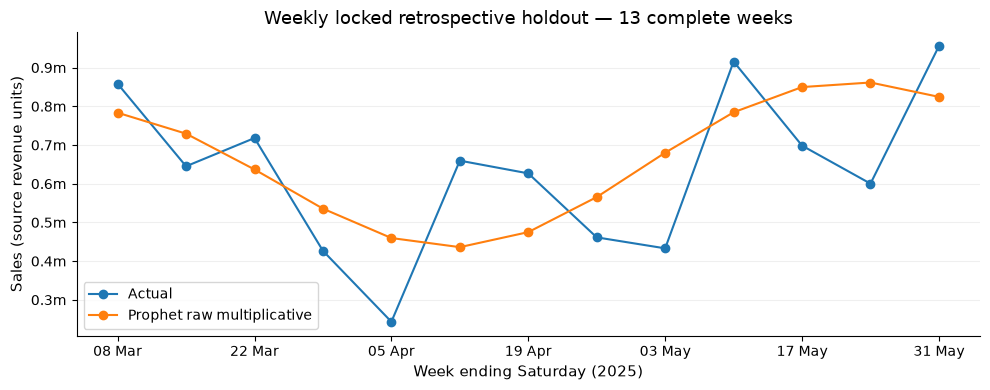

In [31]:
display(numeric_round(weekly_study["retrospective_metrics"][["Model", *METRICS]], 3))
display(numeric_round(weekly_study["retrospective_predictions"]))
display(weekly_figures[1])

### Monthly Results

The forecast covers the three complete months of March, April and May 2025. APE uses each month's actual Sales. WAPE contributions use total Sales across all three months and sum to the overall WAPE.

,MAPE,WAPE,sMAPE,MAE,RMSE,MASE,Bias,Bias_pct
0,9.61,9.31,10.47,257093.18,340192.02,0.32,-210644.38,-7.63


,Date,Actual Sales,Predicted Sales,Absolute Error,APE,WAPE contribution
0,2025-03-31,2.74e+06,2.17e+06,570133.68,20.80,6.88
1,2025-04-30,2.21e+06,2.08e+06,131472.65,5.94,1.59
2,2025-05-31,3.33e+06,3.40e+06,69673.21,2.09,0.84


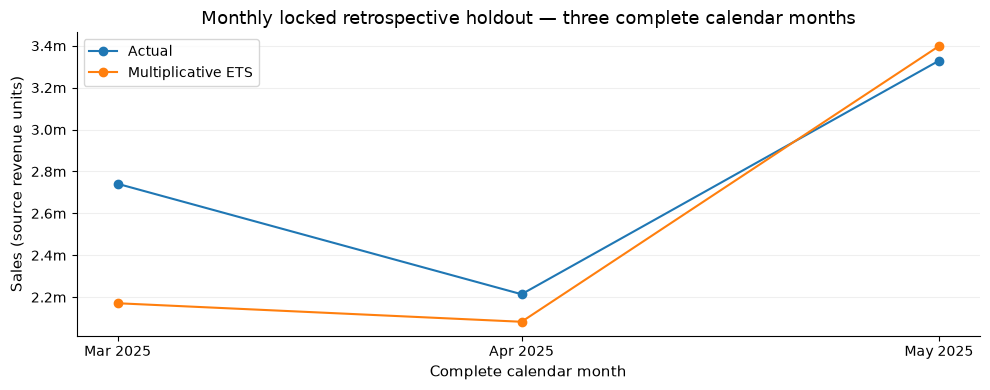

In [32]:
display(numeric_round(monthly_study["retrospective_metrics"][METRICS], 3))
display(numeric_round(monthly_study["retrospective_predictions"]))
display(monthly_figures[1])

## Future Forecasts

The selected settings are refitted on all available complete history without retuning. Forecasts begin after the workbook's May 31, 2025 cutoff. The workbook contains no outcomes for these future dates, and no prediction intervals are estimated.

,Date,Forecast Sales
0,2025-06-07,7.49e+05
1,2025-06-14,6.97e+05
2,2025-06-21,6.57e+05
3,2025-06-28,6.42e+05
4,2025-07-05,6.56e+05
5,2025-07-12,6.99e+05
6,2025-07-19,7.70e+05
7,2025-07-26,8.65e+05
8,2025-08-02,9.79e+05
9,2025-08-09,1.10e+06


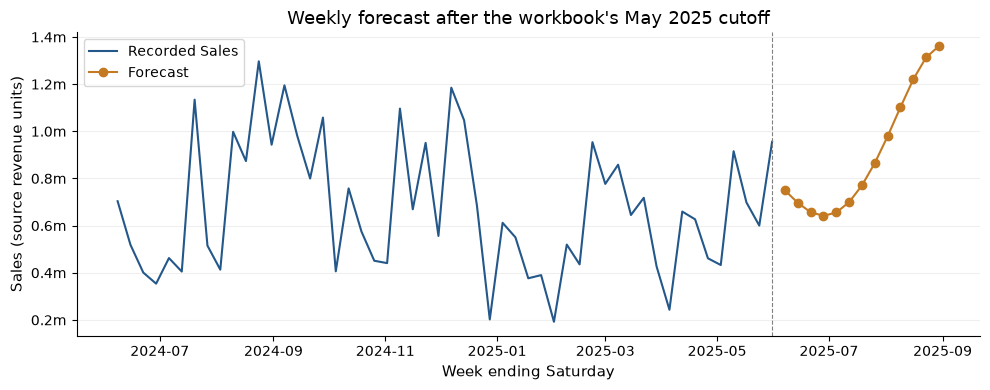

,Date,Forecast Sales
0,2025-06-30,2.52e+06
1,2025-07-31,3.61e+06
2,2025-08-31,5.34e+06


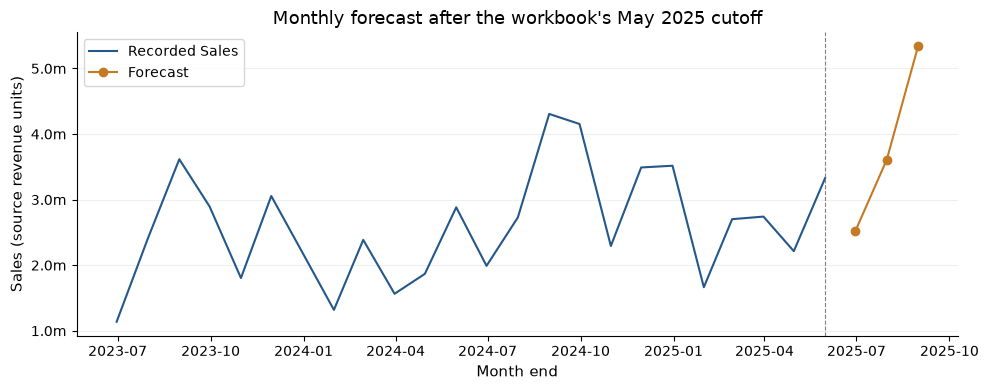

In [33]:
display(numeric_round(weekly_study["future"]))
display(weekly_figures[2])
display(numeric_round(monthly_study["future"]))
display(monthly_figures[2])

## Weekly vs Monthly

Weekly and monthly percentage errors are not directly comparable: they predict different aggregation levels. Monthly aggregation smooths short-term variation and allows errors within a month to offset.

Weekly development scores describe the selected Prophet family with inner tuning. Monthly development scores describe selection across the smaller monthly pool. The retrospective rows evaluate the settings selected for those periods.

In [34]:
executive = executive_comparison(studies)
weekly_cv = r_primary.loc[r_champion]
weekly_holdout = r_final_metrics.loc[r_champion]
monthly_cv = monthly_study["comparison"].iloc[0]
monthly_holdout = r_final_month_metrics.iloc[0]
executive_tasks = pd.DataFrame({
    "Weekly": ["Weekly Sales", "Sunday–Saturday", "13 weeks", "4 × 13 weeks", r_champion,
               f"{weekly_cv.MAPE:.2f}%", f"{weekly_cv.WAPE:.2f}%", f"{weekly_holdout.MAPE:.2f}%", f"{weekly_holdout.WAPE:.2f}%"],
    "Monthly": ["Monthly Sales", "Complete calendar months", "3 complete months", "4 × 3 months", "Multiplicative ETS",
                f"{monthly_cv.MAPE:.2f}%", f"{monthly_cv.WAPE:.2f}%", f"{monthly_holdout.MAPE:.2f}%", f"{monthly_holdout.WAPE:.2f}%"],
}, index=["Target", "Frequency", "Horizon", "Development folds", "Selected / final model", "Development MAPE", "Development WAPE", "Retrospective MAPE", "Retrospective WAPE"])
display(executive_tasks)
display(pd.DataFrame([{ "Frequency": label, "Folds": len(frame),
    "Folds MAPE <10%": int(frame.MAPE.lt(10).sum()), "Folds WAPE <10%": int(frame.WAPE.lt(10).sum())}
    for label, frame in [("Weekly", r_dev_metrics.loc[r_dev_metrics.Model.eq(r_champion)]), ("Monthly", r_month_metrics)]]))

,Weekly,Monthly
Target,Weekly Sales,Monthly Sales
Frequency,Sunday–Saturday,Complete calendar months
Horizon,13 weeks,3 complete months
Development folds,4 × 13 weeks,4 × 3 months
Selected / final model,Prophet raw multiplicative,Multiplicative ETS
Development MAPE,33.44%,10.99%
Development WAPE,27.97%,11.53%
Retrospective MAPE,29.13%,9.61%
Retrospective WAPE,23.87%,9.31%


,Frequency,Folds,Folds MAPE <10%,Folds WAPE <10%
0,Weekly,4,0,0
1,Monthly,4,2,1


## Limitations

- Fewer than four annual cycles are available. Nested validation limits direct leakage, but broad exploration of families, transformations and features still creates model-selection uncertainty.
- The 2022 recording pattern, ambiguous order keys and zero-record days need source-system clarification. Promotions, prices, stockouts and future structural changes are unavailable to the forecasts.
- The retrospective periods were previously examined, so they do not provide independent confirmation. March 1, 2025 also lies in weekly development but in the monthly retrospective period.

## Conclusion

Development selection retained multiplicative Prophet for weekly forecasts and ETS for monthly forecasts. Saved retrospective WAPE is 23.87% weekly and 9.31% monthly. The different horizons and aggregation levels prevent a direct accuracy ranking. New observations after the workbook cutoff are needed to test whether these choices generalize.

In [35]:
display(Markdown(
    "## Conclusion\n\n"
    f"Weekly forecasting remains difficult. The selected multiplicative Prophet model achieved **{weekly_cv.WAPE:.2f}% mean development WAPE** "
    f"and **{weekly_holdout.WAPE:.2f}% WAPE** on the locked retrospective 13-week period.\n\n"
    f"Monthly aggregation was easier to forecast. Monthly model selection achieved **{monthly_cv.MAPE:.2f}% mean development MAPE** "
    f"and **{monthly_cv.WAPE:.2f}% WAPE**. Multiplicative Holt-Winters/ETS achieved **{monthly_holdout.MAPE:.2f}% MAPE** "
    f"and **{monthly_holdout.WAPE:.2f}% WAPE** on March–May 2025.\n\n"
    "The sub-10% result applies only to that monthly retrospective period. It does not establish sub-10% weekly accuracy "
    "or consistent sub-10% monthly performance. Future data are needed for independent confirmation."
))

## Conclusion

Weekly forecasting remains difficult. The selected multiplicative Prophet model achieved **27.97% mean development WAPE** and **23.87% WAPE** on the locked retrospective 13-week period.

Monthly aggregation was easier to forecast. Monthly model selection achieved **10.99% mean development MAPE** and **11.53% WAPE**. Multiplicative Holt-Winters/ETS achieved **9.61% MAPE** and **9.31% WAPE** on March–May 2025.

The sub-10% result applies only to that monthly retrospective period. It does not establish sub-10% weekly accuracy or consistent sub-10% monthly performance. Future data are needed for independent confirmation.

## Technical Appendix

### Complete Model Comparison

The weekly table includes every evaluated family and combined forecast. The monthly comparison describes adaptive selection across its candidate pool. Detailed settings and search records remain available in the notebook's Python objects.

,MAPE,WAPE,sMAPE,MAE,RMSE,MASE,Bias,Bias_pct,Fold-to-fold SD,MAPE SD
Model,,,,,,,,,,
Prophet raw multiplicative,33.44,27.97,29.59,178080.76,216712.01,0.81,-21099.03,-3.49,4.98,9.56
Ensemble inverse-error top 5,37.21,29.22,30.71,186260.43,224171.18,0.84,13700.64,1.75,5.15,11.86
Ensemble median top 5,37.30,29.25,30.83,186288.33,226258.04,0.84,9961.78,1.17,6.25,13.40
Ensemble mean top 3,38.76,29.36,30.74,188054.32,223691.58,0.85,42289.78,6.27,5.69,13.09
Ensemble mean top 2,37.77,29.55,31.05,189126.81,222779.94,0.86,28461.08,3.89,5.76,11.79
Calendar trend Ridge,33.47,30.05,30.97,192616.73,238729.15,0.87,-57907.42,-8.85,4.83,10.77
Bottom-up categories (B=C),36.68,30.12,31.54,189760.53,220930.98,0.86,-23717.04,-3.64,4.01,10.80
Dynamic harmonic regression,39.53,30.16,31.05,193294.99,237380.13,0.88,42928.69,6.06,6.99,15.79
Calendar exposure Gamma,35.66,30.16,31.31,192169.26,230784.67,0.87,3125.80,0.38,5.69,6.53


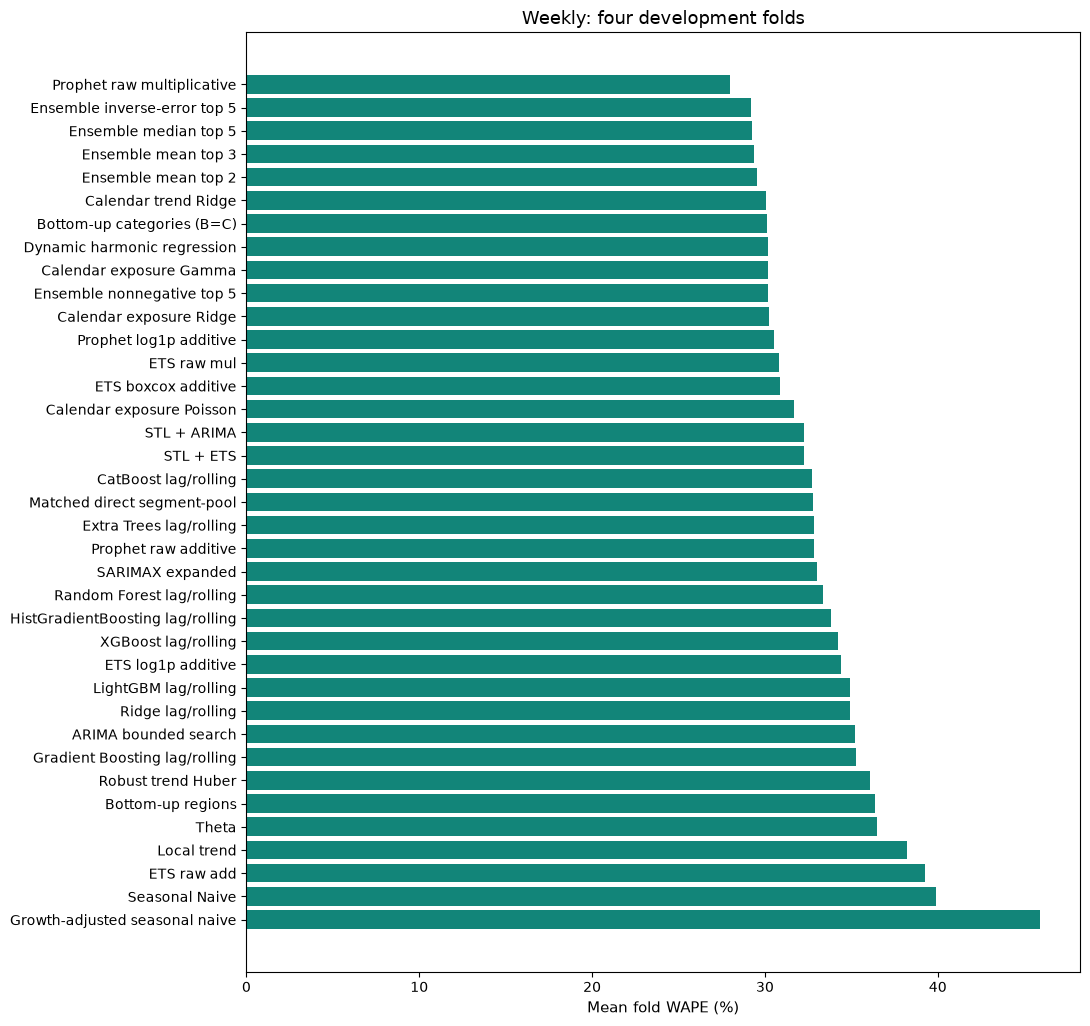

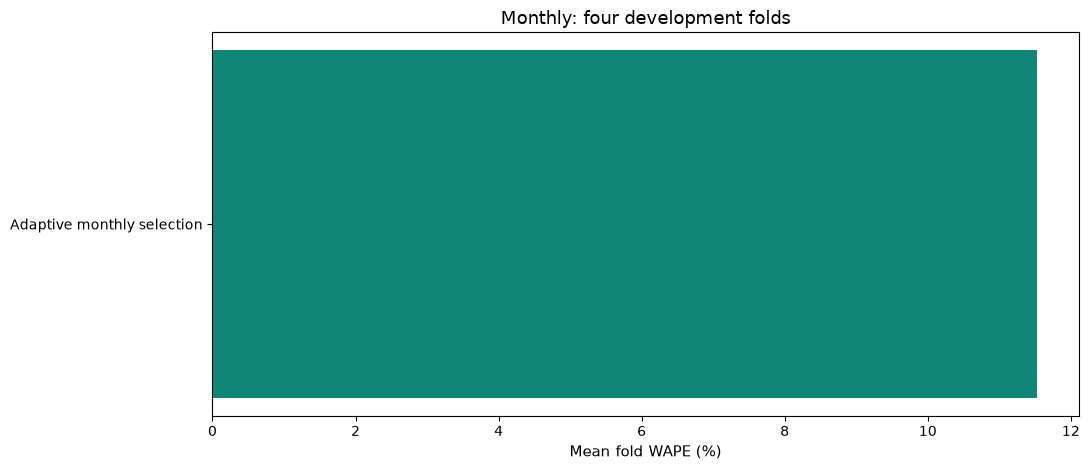

,Frequency,Model,Training end,Settings
0,Weekly,Prophet raw multiplicative,2025-03-01,"{'tx': 'raw', 'mode': 'multiplicative', 'cps':..."
1,Monthly,ETS / Holt-Winters,2025-02-28,"{'tx': 'raw', 'trend': 'add', 'seasonal': 'mul..."


,Candidate configurations
Broad family,
ARIMA,36
CatBoost,12
Dynamic Harmonic Regression,90
ETS / Holt-Winters,22
Extra Trees,12
Gamma Regression,36
Gradient Boosting,12
Growth-adjusted Seasonal Naive,3
HistGradientBoosting,12


Candidate configurations
Broad family                   kind                                    
ARIMA / SARIMA                 arima                                 12
                               sarima                                 4
ETS / Holt-Winters             ets                                    8
Harmonic / calendar regression calendar_ridge                        30
                               dhr                                    6
Prophet                        prophet                               18
Seasonal Naive                 naive                                  1
Theta                          theta                                  9

In [36]:
with pd.option_context("display.max_rows", None):
    display(numeric_round(r_primary[METRICS + ["Fold-to-fold SD", "MAPE SD"]], 3))
display(weekly_figures[0])
display(monthly_figures[0])
display(selected_settings)
display(weekly_inventory.groupby("Broad family").size().rename("Candidate configurations").to_frame())
display(monthly_inventory.groupby(["Broad family", "kind"]).size().rename("Candidate configurations").to_frame())

### Error by Forecast Horizon

Each weekly lead has only four development observations, making horizon effects difficult to separate from calendar timing. The largest errors remain included in evaluation.

In [37]:
display(numeric_round(r_horizon[["week", *METRICS]], 3))
display(numeric_round(r_new_errors.nlargest(5, "absolute_error")[["week_end", "fold", "forecast_horizon", "actual", "predicted", "absolute_error", "mean_fold_WAPE_contribution_pp"]], 3))

,week,MAPE,WAPE,sMAPE,MAE,RMSE,MASE,Bias,Bias_pct
0,1,42.84,31.49,37.92,262044.48,307114.60,1.19,-138426.49,-16.63
1,2,24.00,25.20,27.56,197717.96,243212.18,0.89,-153183.74,-19.53
2,3,18.92,16.67,18.15,96233.61,116020.20,0.43,-15973.75,-2.77
3,4,57.96,45.69,45.20,215019.49,241097.97,0.98,29434.97,6.25
4,5,34.99,34.69,36.49,174868.26,189806.16,0.79,-41913.82,-8.31
5,6,27.93,27.05,30.40,147507.27,148661.61,0.67,-88126.52,-16.16
6,7,16.38,26.08,20.38,159565.14,283945.53,0.72,-124366.19,-20.33
7,8,27.28,27.91,23.56,119314.29,132658.82,0.54,119314.29,27.91
8,9,82.84,62.59,51.23,244753.39,276951.60,1.11,232366.75,59.42
9,10,24.86,24.87,27.03,211565.36,220023.08,0.96,-149825.65,-17.61


,week_end,fold,forecast_horizon,actual,predicted,absolute_error,mean_fold_WAPE_contribution_pp
1423,2024-07-20,2,7,1.13e+06,568549.57,565659.31,1.57
1443,2024-12-07,4,1,1.19e+06,680525.01,504488.54,1.59
1444,2024-12-14,4,2,1.05e+06,606523.27,439982.85,1.39
1428,2024-08-24,2,12,1.30e+06,875126.05,421591.33,1.17
1433,2024-09-28,3,4,1.06e+06,686905.12,371169.04,0.93


### Aggregation Sensitivity

This secondary experiment forecasts the same 91 days at daily, weekly, biweekly and monthly-piece resolutions. Its monthly buckets can include small partial months, making MAPE unstable; its biweekly target includes a final half-bin.

The weekly row uses calendar regression. These rows describe aggregation sensitivity, separately from the primary weekly and complete-month studies.

In [38]:
display(numeric_round(r_agg_summary[["MAPE", "WAPE", "sMAPE", "n_targets"]], 3))

,MAPE,WAPE,sMAPE,n_targets
Frequency,,,,
Biweekly,23.98,22.94,23.25,7.0
Daily,NaN,65.97,77.48,91.0
Monthly,74.88,19.56,30.99,3.5
Weekly,33.49,27.91,28.82,13.0


### Fit Summary

An accepted fit returned a valid forecast; it was not necessarily selected. Ineligible attempts lack required history or valid input values. Numerical rejections failed convergence or forecast checks. Warnings can overlap these categories, including an initial optimizer attempt followed by a successful fallback.

The summary covers cached weekly and complete-month fits. Aggregation sensitivity uses a separate cache. Detailed records remain in memory; any unrecognized failure is shown explicitly.

In [39]:
# Classify recorded outcomes for display only; do not change fitting or selection.
ineligible_errors = {
    "ValueError: endog must be strictly positive when usingmultiplicative trend or seasonal components.",
    "ValueError: log1p target requires nonnegative Sales",
    "ValueError: Box-Cox requires positive Sales",
    "ValueError: Fewer than 40 usable supervised rows",
    "ValueError: Cannot compute initial seasonals using heuristic method with less than two full seasonal cycles in the data.",
}
numerical_errors = {
    "ValueError: ARIMA optimizer did not converge",
    "ValueError: ETS optimizer did not converge",
    "ValueError: STL+ETS optimizer did not converge",
    "ValueError: Exposure GLM did not converge",
    "ValueError: Nonfinite inverse transform/domain violation",
    "ValueError: Invalid forecast path",
}
fit_records = r_fit_audit.copy()
fit_records["Outcome"] = np.select(
    [fit_records.error.eq(""), fit_records.error.isin(ineligible_errors), fit_records.error.isin(numerical_errors)],
    ["Successful/accepted fits", "Mathematically ineligible attempts", "Numerical candidate rejections"],
    default="Unexpected implementation failures",
)
fit_counts = fit_records.Outcome.value_counts()
fit_summary = pd.DataFrame({"Count": {
    "Fit attempts": len(fit_records),
    **{label: int(fit_counts.get(label, 0)) for label in ["Successful/accepted fits", "Mathematically ineligible attempts", "Numerical candidate rejections"]},
    "Warning-bearing attempts": int(fit_records.warnings.ne("").sum()),
    "Unexpected implementation failures": int(fit_counts.get("Unexpected implementation failures", 0)),
}})
assert fit_counts.sum() == len(r_fit_audit)
display(fit_summary)
unexpected_failures = fit_records.loc[fit_records.Outcome.eq("Unexpected implementation failures")]
if not unexpected_failures.empty:
    display(unexpected_failures[["candidate", "origin", "tag", "error"]])


,Count
Fit attempts,6718
Successful/accepted fits,6667
Mathematically ineligible attempts,45
Numerical candidate rejections,6
Warning-bearing attempts,153
Unexpected implementation failures,0


### Reproducibility and Saved Models

Run `python predict.py --rebuild-study`, or use `python predict.py --rebuild-study --clean-generated` to rebuild generated outputs. `predict.py` executes the notebook's forecasting calculation cells in order using their `forecast_step` metadata. No Jupyter kernel is needed for the script.

Only the two selected full-history models are saved: Prophet JSON and ETS joblib, including the revenue scale needed to invert predictions. Both files are reloaded and checked. These full-history models include the retrospective observations; use the saved prediction tables for past validation results.

Runtime is descriptive, not a selection criterion. Timings depend on hardware, package versions, thread limits and background load. The timing CSV retains the standalone run; the notebook displays its own timings.

In [40]:
for study in studies:
    save_study_tables(study, PROJECT_ROOT)
check_results(globals(), data, PROJECT_ROOT)
notebook_timing = timing_summary(globals(), perf_counter()-started, studies)
if not (PROJECT_ROOT / "tables/timing_summary.csv").exists():
    notebook_timing.to_csv(PROJECT_ROOT / "tables/timing_summary.csv", index=False)
display(numeric_round(notebook_timing, 3))
display(pd.DataFrame([{"Frequency": s["frequency"], "Production model": s["model_path"],
                       "Reload maximum forecast difference": s["reload_max_difference"]} for s in studies]))
print("Data, forecast and saved-model checks passed.")

,Scope,Stage,Seconds
0,Weekly,Experiment total,304.79
1,Monthly,Experiment total,10.01
2,Sensitivity,Experiment total,13.45
3,Both,Shared preparation / presentation / QA,32.65
4,Both,Complete execution,360.89


,Frequency,Production model,Reload maximum forecast difference
0,weekly,models/weekly_prophet.json,0.0
1,monthly,models/monthly_ets.joblib,0.0


Data, forecast and saved-model checks passed.
